<div style="background-color:RGB(30,39,97);">
<h1 style="margin:auto;padding:30px;color:#fff;">ÉTUDE DE MARCHÉ INTERNATIONALE — LA POULE QUI CHANTE</h1>
</div>

**Livrable 2 — ACP, clustering et recommandations**

**Commanditaire :** Patrick, PDG de *La poule qui chante*

**Objectif :** à partir du jeu de données préparé au livrable 1, regrouper les pays par profil et
recommander des marchés cibles pour l'export.

| Etape | Contenu |
|---|---|
| 1 | Configuration et chargement |
| 2 | Préparation : sélection des variables et centrage-réduction |
| 3 | ACP — valeurs propres et choix du nombre d'axes |
| 4 | ACP — cercle des corrélations |
| 5 | ACP — projection des individus |
| 6 | ACP — qualité de représentation et contributions |
| 7 | Interprétation des axes factoriels |
| 8 | Classification ascendante hiérarchique (CAH) |
| 9 | K-means — recherche du nombre optimal de clusters |
| 10 | Comparaison des deux méthodes |
| 11 | Données brutes ou données ACP pour le clustering ? |
| 12 | Caractérisation des clusters |
| 13 | Répartition géographique |
| 14 | Du score statistique au score commercial |
| 15 | Conclusion et recommandations |
| 16 | Limites de l'analyse |

>  **Prérequis : le livrable 1 doit avoir été exécuté en entier.** Il produit le fichier
`Data/clean/donnees_pays_2017.csv` que ce notebook lit en entrée.
En cas d'erreur : **Kernel → Restart & Run All**

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 1 - Configuration et chargement</h2>
</div>

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">1.1 - Importation des librairies</h3>
</div>

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.2f}".format)

NAVY = "#1E2761"
PALETTE = ["#1E2761", "#E07A3F", "#4A9D5F", "#B5485D", "#8562A8", "#3A9FA8"]
sns.set_theme(style="whitegrid")
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

RAW, CLEAN = "../Data/raw/", "../Data/clean/"
RANDOM_STATE = 42          # graine fixe : résultats strictement reproductibles


def titre(txt, char="=", larg=78):
    print(char * larg); print(txt); print(char * larg)


print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 2.3.3 | numpy 2.3.5


> **Note méthodologique :** `RANDOM_STATE = 42` fixe la graine du générateur aléatoire. Le k-means part de centres
initialisés au hasard : sans graine fixe, deux exécutions successives produiraient des clusters
différents. Pour un livrable évalué, c'est rédhibitoire — les chiffres cités dans la présentation
doivent être reproductibles à l'identique.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">1.2 - Chargement du jeu de données préparé</h3>
</div>

In [2]:
df = pd.read_csv(CLEAN + "donnees_pays_2017.csv")
dico = pd.read_csv(CLEAN + "dictionnaire_variables.csv")

titre("JEU DE DONNÉES ISSU DU LIVRABLE 1")
print(f"{df.shape[0]} pays x {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {int(df.isna().sum().sum())}")
print(f"Doublons ISO3      : {int(df.duplicated(subset='iso3').sum())}\n")
display(df.head())

JEU DE DONNÉES ISSU DU LIVRABLE 1
164 pays x 23 colonnes
Valeurs manquantes : 0
Doublons ISO3      : 0



,pays,iso3,continent,population,dispo_volaille_kg,production_volaille,import_volaille,export_volaille,dispo_kcal_totale,proteines_animales,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,taux_dependance_import,taux_autosuffisance,croissance_pop_2010_2018,part_proteines_animales,log_population,log_production_volaille,log_import_volaille,log_export_volaille,log_pib_habitant
0,Afghanistan,AFG,Asie,"36,296.11",1.53,28.00,29.00,0.00,"1,997.00",10.56,525.47,2.65,24.84,4.98,50.88,49.12,27.36,19.52,10.50,3.37,3.40,0.00,6.27
1,Afrique du Sud,ZAF,Afrique,"57,009.76",35.69,"1,667.00",514.00,63.00,"2,987.00",34.56,"6,618.34",1.16,63.33,5.19,24.27,78.71,12.84,41.46,10.95,7.42,6.24,4.16,8.80
2,Albanie,ALB,Europe,"2,884.17",16.36,13.00,38.00,0.00,"3,400.00",66.33,"5,006.36",3.28,55.98,1.99,80.85,27.66,-2.21,55.51,7.97,2.64,3.66,0.00,8.52
3,Algérie,DZA,Afrique,"41,389.19",6.38,275.00,2.00,0.00,"3,345.00",25.70,"4,554.67",1.50,71.32,5.59,0.72,99.28,17.37,27.68,10.63,5.62,1.10,0.00,8.42
4,Allemagne,DEU,Europe,"82,658.41",19.47,"1,514.00",842.00,646.00,"3,559.00",63.09,"45,553.93",2.80,80.98,1.51,48.42,87.06,2.84,60.62,11.32,7.32,6.74,6.47,10.73


<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 2 - Préparation : sélection des variables et centrage-réduction</h2>
</div>

### Quelles variables entrent dans l'ACP ?

Les quinze variables de niveau et de structure, en privilégiant les versions **logarithmiques**
construites au livrable 1 pour les variables de volume très asymétriques.

### Pourquoi centrer et réduire ?

L'ACP travaille sur la **variance**. Or nos variables n'ont ni la même unité ni le même ordre de grandeur :

| Variable | Unité | Amplitude observée |
|---|---|---|
| `pib_habitant` | USD | de 300 à 110 000 |
| `dispo_volaille_kg` | kg/pers/an | de 0 à 72 |
| `pop_urbaine_pct` | % | de 13 à 100 |

Sans traitement, le PIB écraserait tout : sa variance est plusieurs milliers de fois supérieure à
celle de la consommation de volaille, et l'ACP ne décrirait que la variance du PIB.

**Centrer** = soustraire la moyenne, pour que chaque variable soit centrée sur 0.
**Réduire** = diviser par l'écart-type, pour que chaque variable ait un écart-type de 1.

Après ce traitement, toutes les variables pèsent le même poids et s'expriment dans la même unité :
**l'écart-type**.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">2.1 - Sélection des variables</h3>
</div>

In [3]:
BASE = ["population", "dispo_volaille_kg", "production_volaille", "import_volaille",
        "export_volaille", "dispo_kcal_totale", "proteines_animales",
        "pib_habitant", "croissance_pib", "pop_urbaine_pct", "inflation",
        "taux_dependance_import", "taux_autosuffisance",
        "croissance_pop_2010_2018", "part_proteines_animales"]

# Version logarithmique quand elle existe (variables de volume), version brute sinon
VARS = [("log_" + c if "log_" + c in df.columns else c) for c in BASE]

X = df[VARS].copy()
PAYS = df["pays"].values

titre("VARIABLES RETENUES POUR L'ACP")
print(f"{len(VARS)} variables, {len(X)} individus (pays)\n")
for i, v in enumerate(VARS, 1):
    print(f"   {i:>2}. {v}")

VARIABLES RETENUES POUR L'ACP
15 variables, 164 individus (pays)

    1. log_population
    2. dispo_volaille_kg
    3. log_production_volaille
    4. log_import_volaille
    5. log_export_volaille
    6. dispo_kcal_totale
    7. proteines_animales
    8. log_pib_habitant
    9. croissance_pib
   10. pop_urbaine_pct
   11. inflation
   12. taux_dependance_import
   13. taux_autosuffisance
   14. croissance_pop_2010_2018
   15. part_proteines_animales


<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">2.2 - Centrage-réduction</h3>
</div>

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=VARS, index=PAYS)

titre("VÉRIFICATION DU CENTRAGE-RÉDUCTION")
display(pd.DataFrame({
    "moyenne_avant": X.mean().round(2),
    "écart_type_avant": X.std().round(2),
    "moyenne_après": X_scaled_df.mean().round(6),
    "écart_type_après": X_scaled_df.std(ddof=0).round(6),
}))

VÉRIFICATION DU CENTRAGE-RÉDUCTION


,moyenne_avant,écart_type_avant,moyenne_après,écart_type_après
log_population,9.03,1.94,0.00,1.00
dispo_volaille_kg,19.85,15.60,-0.00,1.00
log_production_volaille,4.31,2.35,0.00,1.00
log_import_volaille,2.93,1.87,-0.00,1.00
log_export_volaille,1.59,2.15,0.00,1.00
dispo_kcal_totale,"2,857.02",458.69,0.00,1.00
proteines_animales,36.28,19.72,-0.00,1.00
log_pib_habitant,8.67,1.37,-0.00,1.00
croissance_pib,3.28,3.31,0.00,1.00
pop_urbaine_pct,58.60,21.36,-0.00,1.00


**Analyse et conclusion :**

Après traitement, toutes les variables ont une moyenne de 0 et un écart-type de 1
(aux arrondis de calcul près). Elles sont désormais comparables et pèsent le même poids dans
la construction des axes factoriels.

L'écart entre les colonnes « avant » et « après » donne la mesure du problème résolu : les
écarts-types d'origine allaient de moins de 1 à plusieurs dizaines de milliers.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 3 - ACP — valeurs propres et choix du nombre d'axes</h2>
</div>

L'ACP construit de nouvelles variables, les **composantes principales**, qui sont des
combinaisons linéaires des variables d'origine. La première capture le maximum de variance possible,
la deuxième le maximum de ce qui reste, et ainsi de suite.

Trois critères usuels pour décider combien d'axes conserver :

| Critère | Règle |
|---|---|
| **Kaiser** | conserver les axes de valeur propre supérieure à 1 — un axe doit porter plus d'information qu'une variable seule |
| **Coude** | s'arrêter là où la courbe de l'éboulis décroche |
| **Variance cumulée** | atteindre 70 à 80 % de l'information totale |

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">3.1 - Valeurs propres et variance expliquée</h3>
</div>

In [5]:
pca = PCA(n_components=len(VARS), random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)

vp = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_ratio)

tab_vp = pd.DataFrame({
    "axe": [f"F{i+1}" for i in range(len(vp))],
    "valeur_propre": vp.round(3),
    "variance_%": var_ratio.round(2),
    "variance_cumulée_%": var_cum.round(2),
    "critère_Kaiser": np.where(vp > 1, "retenu", "-"),
})

titre("VALEURS PROPRES ET VARIANCE EXPLIQUÉE")
display(tab_vp)

n_kaiser = int((vp > 1).sum())
n_70 = int(np.argmax(var_cum >= 70) + 1)
print(f"\nCritère de Kaiser (valeur propre > 1) : {n_kaiser} axes")
print(f"Seuil de 70 % de variance cumulée     : {n_70} axes")

VALEURS PROPRES ET VARIANCE EXPLIQUÉE


,axe,valeur_propre,variance_%,variance_cumulée_%,critère_Kaiser
0,F1,5.66,37.51,37.51,retenu
1,F2,3.10,20.50,58.01,retenu
2,F3,1.48,9.80,67.81,retenu
3,F4,1.12,7.41,75.22,retenu
4,F5,0.77,5.09,80.31,-
5,F6,0.68,4.53,84.84,-
6,F7,0.62,4.11,88.95,-
7,F8,0.47,3.10,92.05,-
8,F9,0.34,2.28,94.33,-
9,F10,0.30,2.00,96.34,-



Critère de Kaiser (valeur propre > 1) : 4 axes
Seuil de 70 % de variance cumulée     : 4 axes


<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">3.2 - Éboulis des valeurs propres</h3>
</div>

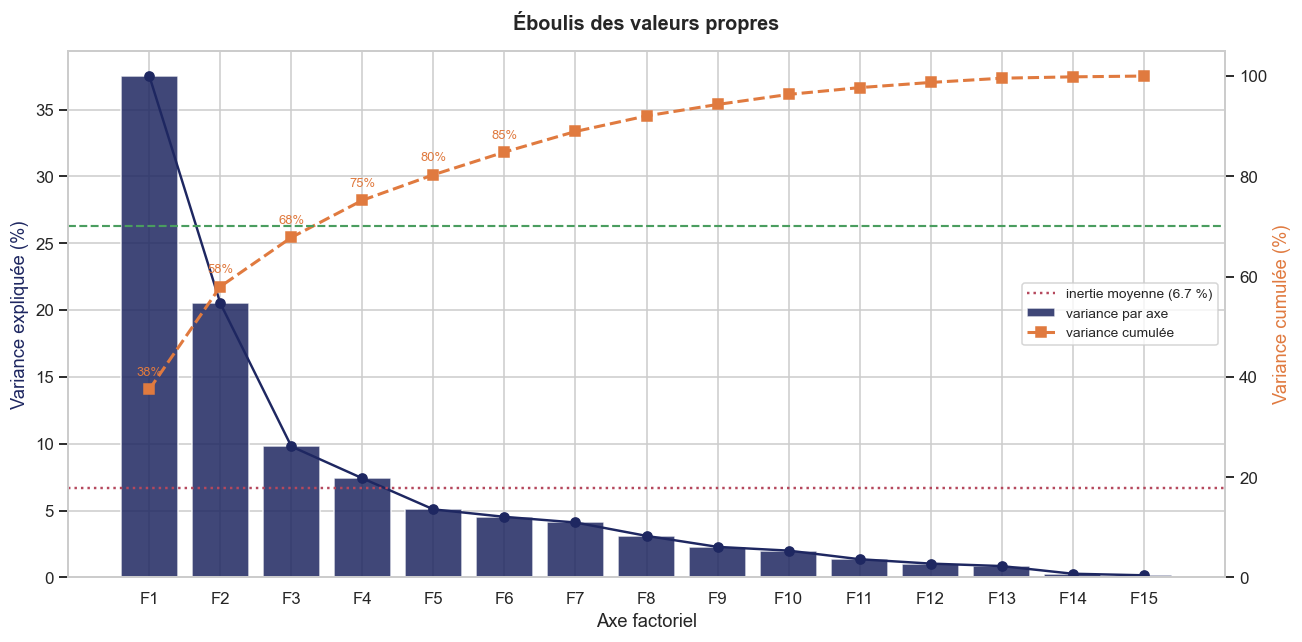

In [6]:
fig, ax1 = plt.subplots(figsize=(12, 6))
x = np.arange(1, len(vp) + 1)

ax1.bar(x, var_ratio, color=NAVY, alpha=.85, edgecolor="white", label="variance par axe")
ax1.plot(x, var_ratio, "o-", color=NAVY, lw=1.6, ms=6)
ax1.axhline(100 / len(VARS), color="#B5485D", ls=":", lw=1.6,
            label=f"inertie moyenne ({100/len(VARS):.1f} %)")
ax1.set_xlabel("Axe factoriel")
ax1.set_ylabel("Variance expliquée (%)", color=NAVY)
ax1.set_xticks(x); ax1.set_xticklabels([f"F{i}" for i in x])

ax2 = ax1.twinx()
ax2.plot(x, var_cum, "s--", color="#E07A3F", lw=2, ms=6, label="variance cumulée")
ax2.axhline(70, color="#4A9D5F", ls="--", lw=1.4)
ax2.set_ylabel("Variance cumulée (%)", color="#E07A3F")
ax2.set_ylim(0, 105); ax2.grid(False)
for i, c in enumerate(var_cum[:6], 1):
    ax2.annotate(f"{c:.0f}%", (i, c), textcoords="offset points",
                 xytext=(0, 9), ha="center", fontsize=8.5, color="#E07A3F")

l1, lab1 = ax1.get_legend_handles_labels()
l2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lab1 + lab2, loc="center right", fontsize=9)
plt.title("Éboulis des valeurs propres", pad=14)
plt.tight_layout()
plt.show()

**Ce que ce graphique montre :**

Les **barres bleues** donnent la part de variance portée par chaque axe, la **courbe
orange** la variance cumulée. Le trait rouge pointillé marque l'inertie moyenne : un axe situé
en dessous porte moins d'information qu'une variable prise isolément.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">3.3 - Décision : nombre d'axes retenus</h3>
</div>

In [7]:
N_AXES = 4

titre("NOMBRE D'AXES RETENUS")
print(f"Axes conservés : {N_AXES}")
print(f"Variance cumulée : {var_cum[N_AXES-1]:.1f} %\n")
print("Justification :")
print(f"  • critère de Kaiser  : {n_kaiser} axes ont une valeur propre > 1")
print(f"  • coude de l'éboulis : décrochement net entre F2 et F3")
print(f"  • variance cumulée   : {var_cum[N_AXES-1]:.1f} %, au-delà du seuil usuel de 70 %")

coords_ret = coords[:, :N_AXES]
coords_df = pd.DataFrame(coords_ret, columns=[f"F{i+1}" for i in range(N_AXES)], index=PAYS)

NOMBRE D'AXES RETENUS
Axes conservés : 4
Variance cumulée : 75.2 %

Justification :
  • critère de Kaiser  : 4 axes ont une valeur propre > 1
  • coude de l'éboulis : décrochement net entre F2 et F3
  • variance cumulée   : 75.2 %, au-delà du seuil usuel de 70 %


**Analyse et conclusion :**

**Les trois critères convergent sur 4 axes**, ce qui rend la décision particulièrement solide.

+ Le critère de Kaiser retient exactement 4 axes : F4 a une valeur propre de 1,11 et F5 tombe à 0,75.
+ L'éboulis décroche nettement entre F2 (20,5 %) et F3 (9,8 %) : la marche est visible à l'œil.
+ La variance cumulée atteint 75,2 % sur 4 axes, au-delà du seuil usuel de 70 %.

Quand les trois critères s'accordent, il n'y a pas d'arbitrage à faire. Les axes F1 et F2, qui
portent à eux seuls 58 % de l'information, seront commentés en priorité ; F3 et F4 servent de
complément d'analyse.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 4 - ACP — cercle des corrélations</h2>
</div>

Le cercle des corrélations montre **comment chaque variable d'origine se projette** sur les
nouveaux axes.

| Observation | Interprétation |
|---|---|
| flèche **longue**, proche du cercle | variable **bien représentée** sur ce plan |
| flèches dans la **même direction** | variables **corrélées positivement** |
| flèches **opposées** | variables **corrélées négativement** |
| flèches à **90°** | variables **indépendantes** |
| flèche **courte**, proche du centre | variable **mal représentée** — à ne pas interpréter ici |

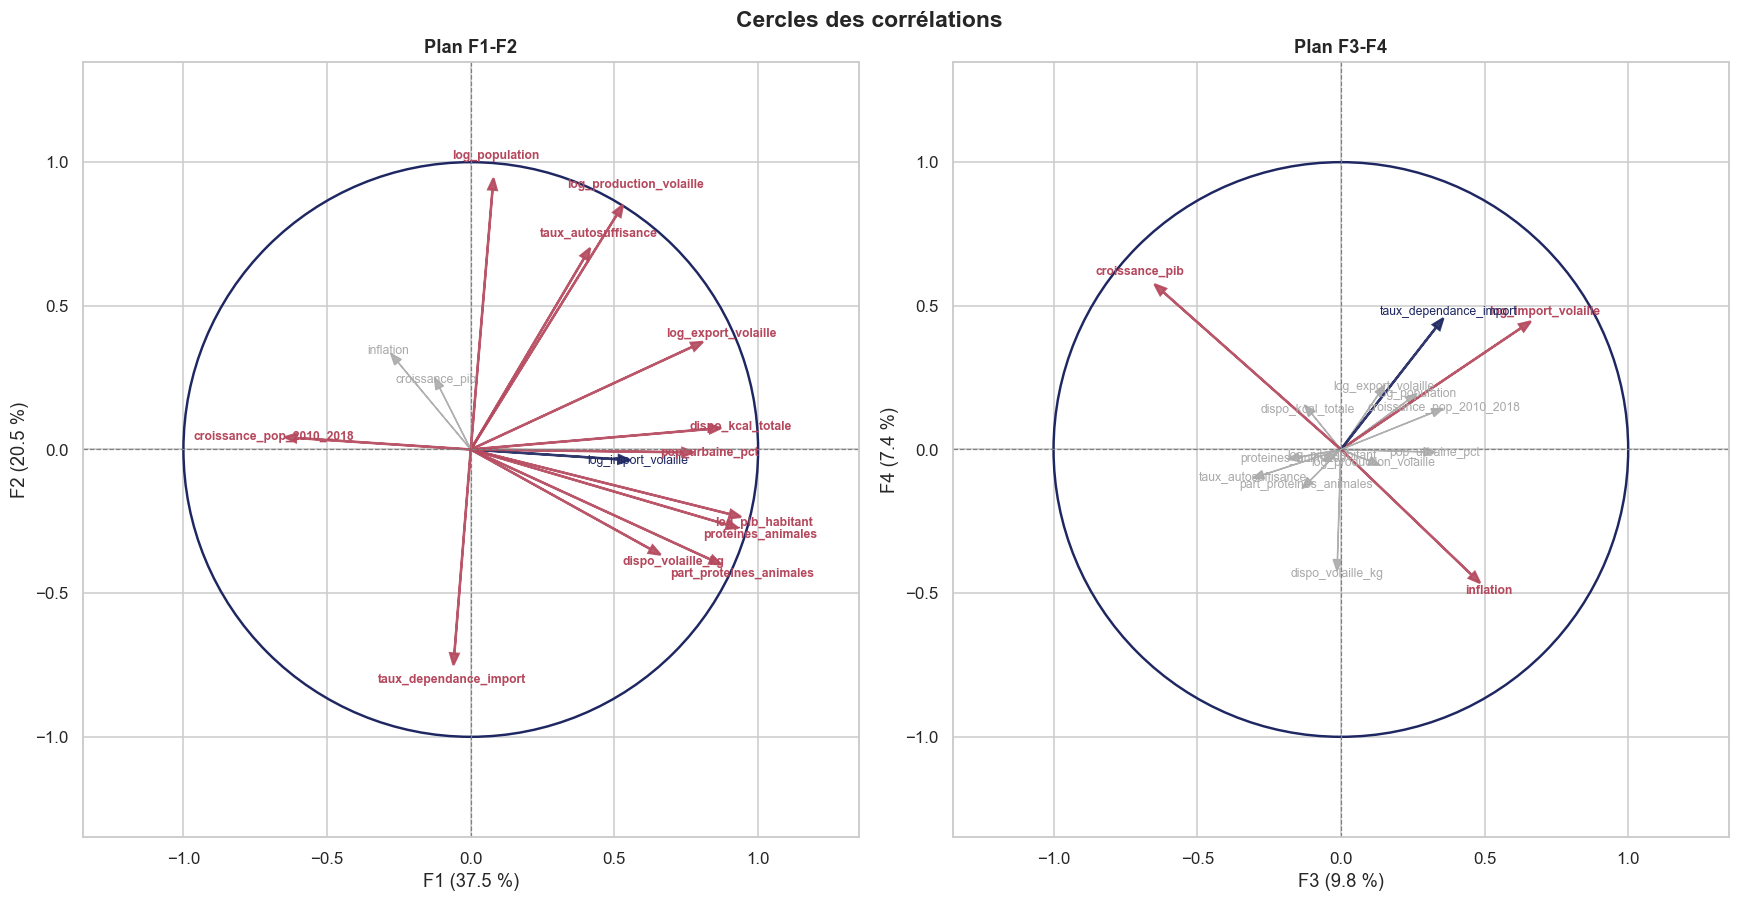

Code couleur : rouge = bien représentée (>0,6) | bleu = correcte (>0,4)
               gris  = mal représentée sur ce plan, à ne pas interpréter


In [8]:
# Coordonnées des variables = corrélation entre la variable et la composante
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings[:, :N_AXES],
                           columns=[f"F{i+1}" for i in range(N_AXES)], index=VARS)


def cercle_correlations(axe_x, axe_y, ax):
    ax.add_artist(plt.Circle((0, 0), 1, fill=False, color=NAVY, lw=1.6))
    ax.axhline(0, color="grey", lw=.8, ls="--")
    ax.axvline(0, color="grey", lw=.8, ls="--")
    for i, var in enumerate(VARS):
        x_, y_ = loadings[i, axe_x], loadings[i, axe_y]
        qualite = np.sqrt(x_**2 + y_**2)
        couleur = "#B5485D" if qualite > .6 else (NAVY if qualite > .4 else "#AAAAAA")
        ax.arrow(0, 0, x_, y_, head_width=.03, head_length=.04,
                 color=couleur, lw=1.5 if qualite > .4 else .9, alpha=.9)
        ax.text(x_ * 1.13, y_ * 1.13, var, fontsize=8, ha="center", va="center",
                color=couleur, fontweight="bold" if qualite > .6 else "normal")
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
    ax.set_xlabel(f"F{axe_x+1} ({var_ratio[axe_x]:.1f} %)")
    ax.set_ylabel(f"F{axe_y+1} ({var_ratio[axe_y]:.1f} %)")
    ax.set_title(f"Plan F{axe_x+1}-F{axe_y+1}", fontsize=12)
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 2, figsize=(16, 8))
cercle_correlations(0, 1, axes[0])
cercle_correlations(2, 3, axes[1])
fig.suptitle("Cercles des corrélations", fontsize=15, fontweight="bold", y=.99)
plt.tight_layout()
plt.show()

print("Code couleur : rouge = bien représentée (>0,6) | bleu = correcte (>0,4)")
print("               gris  = mal représentée sur ce plan, à ne pas interpréter")

**Ce que ce graphique montre :**

Chaque flèche est une variable. Sa **longueur** mesure la qualité de sa représentation
sur le plan, sa **direction** indique à quel axe elle contribue et dans quel sens.
Les variables grisées sont mal représentées sur le plan affiché : leur position n'est pas interprétable.

**Analyse et conclusion :**

**Sur le plan F1-F2**, deux faisceaux de flèches se détachent nettement.

Un premier faisceau pointe vers la droite : PIB par habitant, protéines animales, part de protéines
animales, calories totales, urbanisation, consommation de volaille. Ces variables sont fortement
corrélées entre elles et définissent l'axe horizontal. À l'opposé, seule la croissance démographique
pointe vers la gauche.

Un second faisceau pointe vers le haut : population, production de volaille, taux d'autosuffisance.
Le taux de dépendance aux importations pointe exactement à l'inverse, vers le bas.

Les deux faisceaux sont approximativement **perpendiculaires**, ce qui confirme que richesse et
taille productive sont deux dimensions **indépendantes** du marché mondial de la volaille. C'est
précisément ce que l'analyse bivariée du livrable 1 laissait présager.

**Sur le plan F3-F4**, la plupart des flèches sont courtes et grisées. Seules l'inflation, la
croissance du PIB et les importations y sont correctement représentées.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">4.2 - Tableau des corrélations variables / axes</h3>
</div>

In [9]:
tab = loadings_df.round(3).copy()
tab["qualité_F1F2"] = np.sqrt(loadings_df["F1"]**2 + loadings_df["F2"]**2).round(3)

titre("CORRÉLATIONS VARIABLES - AXES FACTORIELS")
display(tab.sort_values("F1", ascending=False)
          .style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1,
                                     subset=[f"F{i+1}" for i in range(N_AXES)]))

CORRÉLATIONS VARIABLES - AXES FACTORIELS


,F1,F2,F3,F4,qualité_F1F2
log_pib_habitant,0.902000,-0.225000,-0.028000,-0.019000,0.930000
proteines_animales,0.892000,-0.262000,-0.147000,-0.027000,0.930000
part_proteines_animales,0.835000,-0.383000,-0.107000,-0.108000,0.919000
dispo_kcal_totale,0.831000,0.071000,-0.101000,0.124000,0.835000
log_export_volaille,0.772000,0.358000,0.131000,0.192000,0.850000
pop_urbaine_pct,0.736000,-0.010000,0.289000,-0.008000,0.736000
dispo_volaille_kg,0.626000,-0.347000,-0.012000,-0.383000,0.715000
log_import_volaille,0.514000,-0.034000,0.628000,0.423000,0.516000
log_production_volaille,0.509000,0.817000,0.100000,-0.040000,0.963000
taux_autosuffisance,0.395000,0.667000,-0.270000,-0.088000,0.775000


<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 5 - ACP — projection des individus</h2>
</div>

Chaque pays est désormais positionné dans le nouvel espace factoriel. Deux pays proches sur
le graphique ont des **profils similaires** sur l'ensemble des quinze variables.

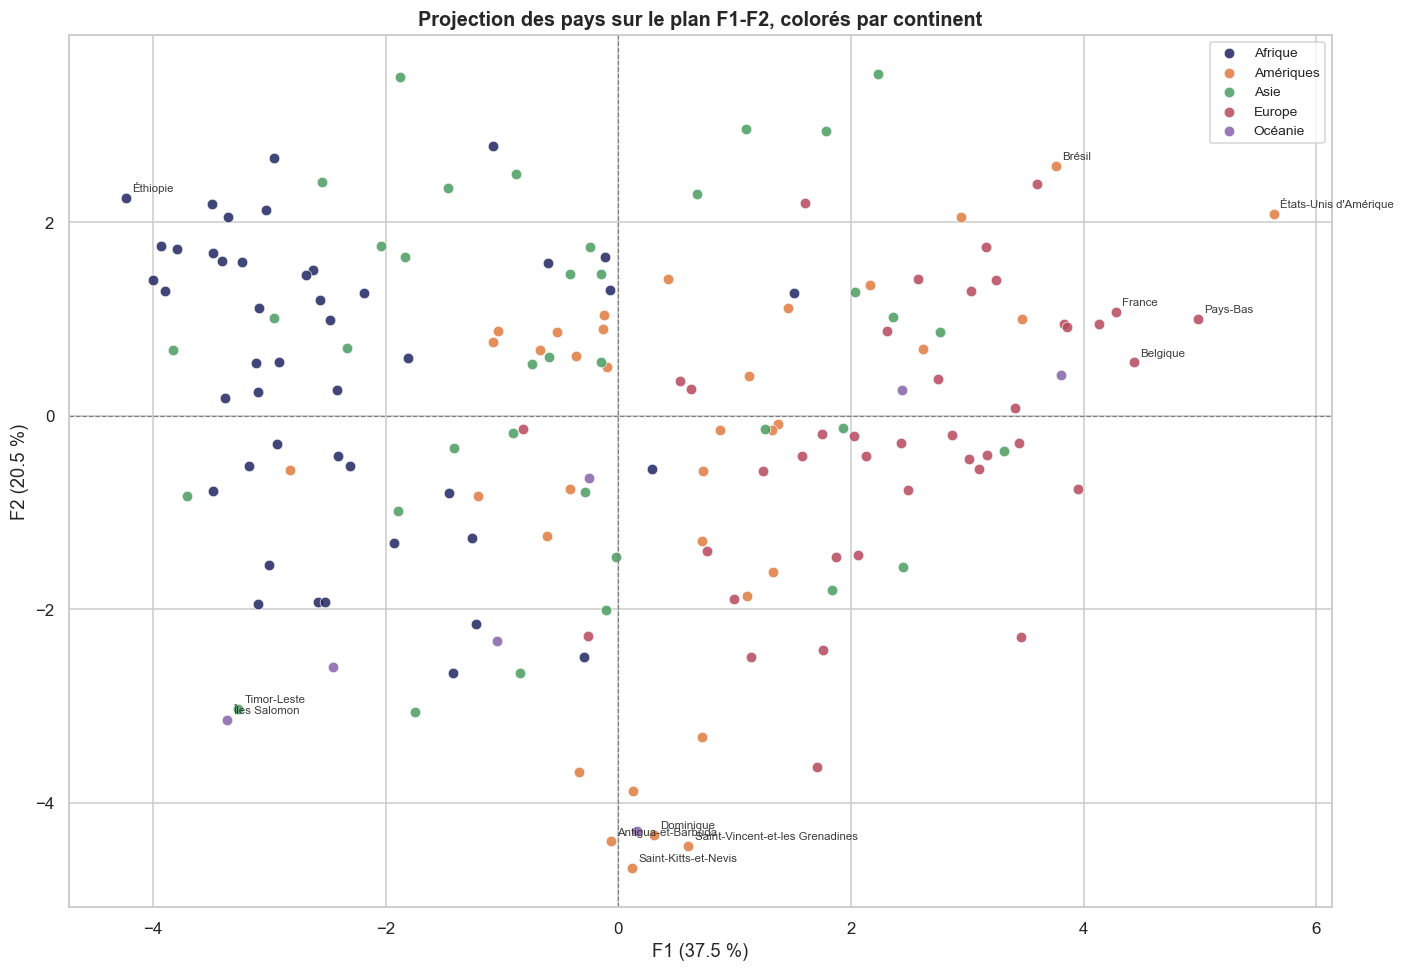

In [10]:
def projeter(axe_x, axe_y, couleurs=None, titre_g="", legende="", ax=None,
             annoter=12, palette=None):
    seul = ax is None
    if seul:
        fig, ax = plt.subplots(figsize=(13, 9))
    if couleurs is None:
        ax.scatter(coords[:, axe_x], coords[:, axe_y], s=45, alpha=.75, color=NAVY)
    else:
        pal = palette or PALETTE
        for i, m in enumerate(sorted(pd.Series(couleurs).unique(), key=str)):
            msk = np.array(couleurs) == m
            ax.scatter(coords[msk, axe_x], coords[msk, axe_y], s=48, alpha=.85,
                       color=pal[i % len(pal)], label=f"{legende}{m}",
                       edgecolor="white", linewidth=.5)
        ax.legend(fontsize=9, loc="best")
    ax.axhline(0, color="grey", lw=.8, ls="--")
    ax.axvline(0, color="grey", lw=.8, ls="--")

    # On annote les pays les plus éloignés du centre : les plus caractéristiques
    dist = np.sqrt(coords[:, axe_x]**2 + coords[:, axe_y]**2)
    for i in np.argsort(dist)[-annoter:]:
        ax.annotate(PAYS[i], (coords[i, axe_x], coords[i, axe_y]),
                    fontsize=7.5, alpha=.9, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(f"F{axe_x+1} ({var_ratio[axe_x]:.1f} %)")
    ax.set_ylabel(f"F{axe_y+1} ({var_ratio[axe_y]:.1f} %)")
    ax.set_title(titre_g or f"Projection des pays — plan F{axe_x+1}-F{axe_y+1}")
    if seul:
        plt.tight_layout(); plt.show()


projeter(0, 1, couleurs=df["continent"].tolist(),
         titre_g="Projection des pays sur le plan F1-F2, colorés par continent")

**Ce que ce graphique montre :**

Chaque point est un pays, coloré par continent. Les pays les plus éloignés du centre
sont annotés : ce sont les plus caractéristiques, ceux qui définissent les extrémités des axes.

**Analyse et conclusion :**

Le nuage a une forme en éventail caractéristique.

À **droite** se regroupent l'Europe et l'Amérique du Nord : pays riches, urbanisés, au régime
carné. À **gauche**, l'Afrique subsaharienne et l'Asie du Sud : forte croissance démographique,
régime végétal.

En **haut**, isolés, les géants démographiques et productifs : Chine, Inde, États-Unis, Brésil.
En **bas**, les petits pays importateurs.

Point essentiel : **les continents se chevauchent largement**. Les couleurs ne forment pas des
blocs séparés. Un continent n'est donc pas un groupe homogène, ce qui confirme l'analyse bivariée
du livrable 1 et justifie de construire les groupes sur des critères économiques plutôt que
géographiques.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">5.2 - Plans F1-F2 et F3-F4 côte à côte</h3>
</div>

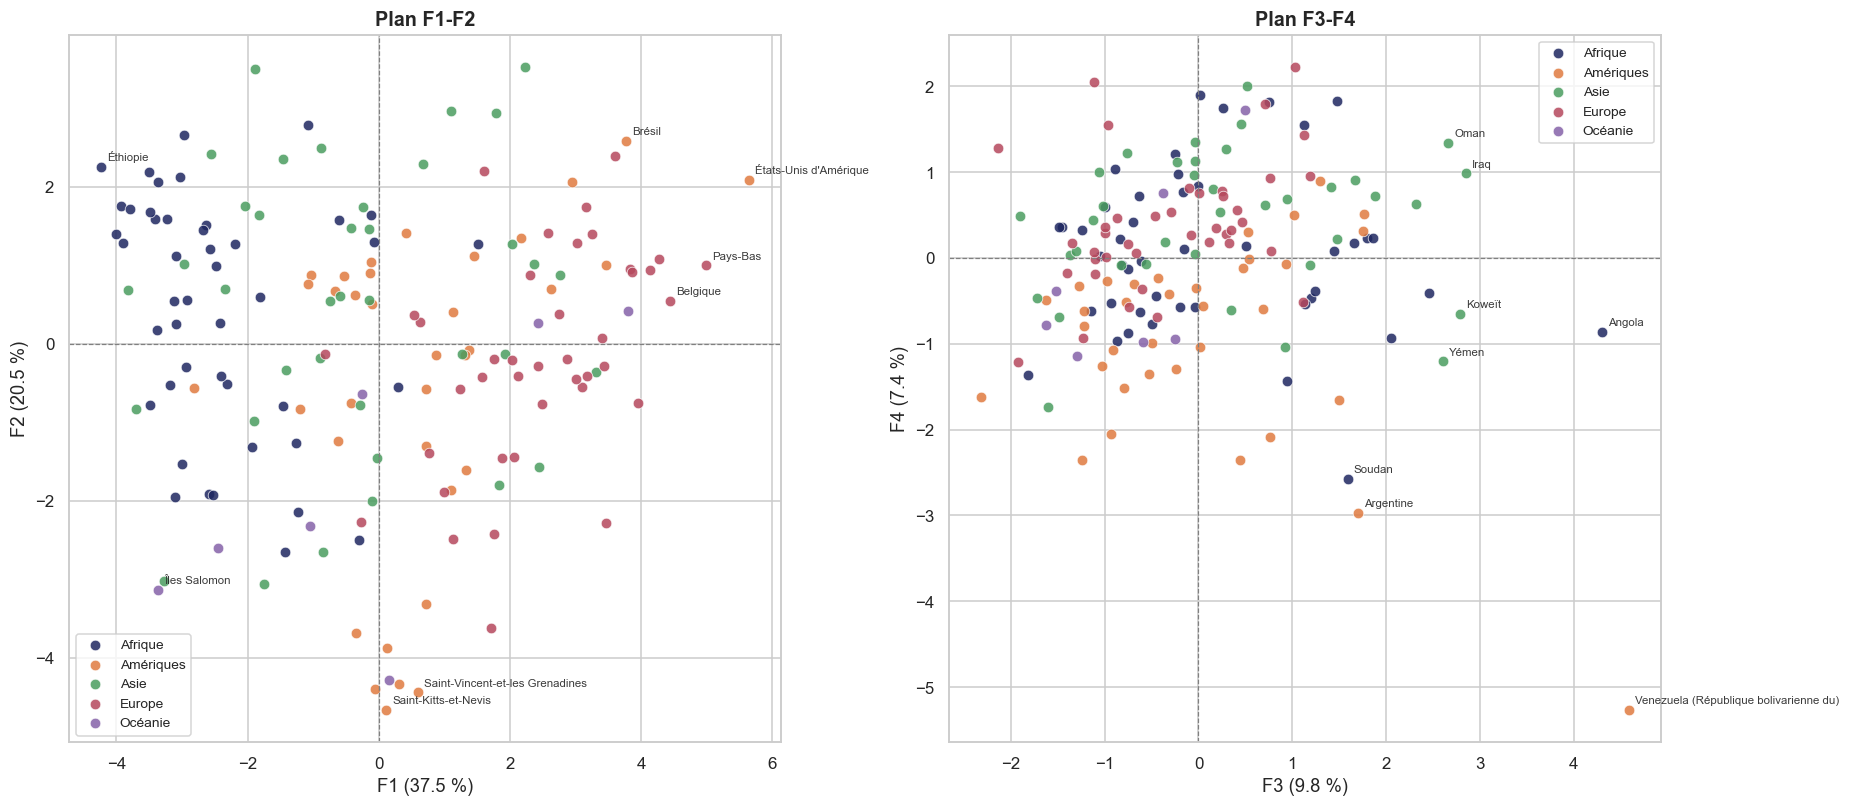

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
projeter(0, 1, couleurs=df["continent"].tolist(), ax=axes[0], titre_g="Plan F1-F2", annoter=8)
projeter(2, 3, couleurs=df["continent"].tolist(), ax=axes[1], titre_g="Plan F3-F4", annoter=8)
plt.tight_layout()
plt.show()

**Analyse et conclusion :**

Le plan F3-F4 présente un nuage beaucoup plus compact et sans structure continentale
apparente. C'est cohérent : ces deux axes ne portent que 17 % de la variance et décrivent des
situations macro-économiques conjoncturelles (inflation, croissance du PIB), qui ne suivent pas
les frontières géographiques.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 6 - ACP — qualité de représentation et contributions</h2>
</div>

Deux indicateurs complètent l'analyse.

Le **cos²** mesure la **qualité de représentation** d'un pays sur un plan. Proche de 1, le pays est
bien décrit ; proche de 0, sa position sur le graphique n'est pas interprétable.

La **contribution** mesure le poids d'un pays dans la construction d'un axe. Une contribution très
élevée signale un individu qui « tire » l'axe à lui seul.

In [12]:
d2 = (coords ** 2).sum(axis=1)
cos2 = (coords ** 2) / d2[:, None]
cos2_df = pd.DataFrame(cos2[:, :N_AXES],
                       columns=[f"cos2_F{i+1}" for i in range(N_AXES)], index=PAYS)
cos2_df["cos2_F1F2"] = cos2_df["cos2_F1"] + cos2_df["cos2_F2"]

contrib = (coords ** 2) / (coords ** 2).sum(axis=0)
contrib_df = pd.DataFrame(contrib[:, :N_AXES] * 100,
                          columns=[f"contrib_F{i+1}_%" for i in range(N_AXES)], index=PAYS)

titre("PAYS LES MIEUX REPRÉSENTÉS SUR LE PLAN F1-F2")
display(cos2_df.nlargest(10, "cos2_F1F2").round(3))

titre("PAYS LES MOINS BIEN REPRÉSENTÉS (à interpréter avec prudence)")
display(cos2_df.nsmallest(10, "cos2_F1F2").round(3))

titre("PAYS CONTRIBUANT LE PLUS À LA CONSTRUCTION DE F1")
display(contrib_df.nlargest(10, "contrib_F1_%").round(2))
print(f"Contribution moyenne attendue si tous les pays pesaient pareil : {100/len(PAYS):.2f} %")

PAYS LES MIEUX REPRÉSENTÉS SUR LE PLAN F1-F2


,cos2_F1,cos2_F2,cos2_F3,cos2_F4,cos2_F1F2
Espagne,0.88,0.05,0.01,0.01,0.93
Danemark,0.90,0.03,0.00,0.03,0.93
République-Unie de Tanzanie,0.68,0.25,0.03,0.01,0.93
Madagascar,0.76,0.15,0.01,0.03,0.91
Rwanda,0.81,0.10,0.04,0.01,0.91
France,0.83,0.05,0.03,0.04,0.89
Italie,0.74,0.14,0.00,0.01,0.88
États-Unis d'Amérique,0.78,0.11,0.01,0.00,0.88
Ouganda,0.73,0.15,0.01,0.01,0.88
Canada,0.81,0.07,0.02,0.01,0.87


PAYS LES MOINS BIEN REPRÉSENTÉS (à interpréter avec prudence)


,cos2_F1,cos2_F2,cos2_F3,cos2_F4,cos2_F1F2
Venezuela (République bolivarienne du),0.00,0.02,0.37,0.49,0.02
Jordanie,0.00,0.03,0.23,0.01,0.04
Maurice,0.01,0.04,0.47,0.26,0.06
Bosnie-Herzégovine,0.06,0.01,0.29,0.01,0.07
Guyana,0.02,0.06,0.53,0.26,0.07
Liban,0.05,0.03,0.14,0.00,0.08
El Salvador,0.00,0.09,0.03,0.06,0.09
Fidji,0.01,0.09,0.55,0.13,0.10
Bolivie (État plurinational de),0.00,0.12,0.15,0.23,0.12
Paraguay,0.03,0.10,0.41,0.03,0.13


PAYS CONTRIBUANT LE PLUS À LA CONSTRUCTION DE F1


,contrib_F1_%,contrib_F2_%,contrib_F3_%,contrib_F4_%
États-Unis d'Amérique,3.45,0.87,0.10,0.01
Pays-Bas,2.69,0.20,0.21,1.76
Belgique,2.13,0.06,0.44,2.72
France,1.98,0.23,0.24,0.48
Éthiopie,1.94,1.00,0.42,0.19
Allemagne,1.85,0.18,0.52,1.13
Rwanda,1.74,0.39,0.36,0.15
Danemark,1.69,0.11,0.03,0.29
Madagascar,1.68,0.61,0.10,0.32
Niger,1.65,0.33,0.17,0.29


Contribution moyenne attendue si tous les pays pesaient pareil : 0.61 %


**Analyse et conclusion :**

Les pays les mieux représentés sur le plan F1-F2 sont ceux dont le profil est le plus
« typique » d'un des pôles : très riches et carnés, ou très pauvres et végétariens.

Les pays mal représentés ont un cos² faible sur F1-F2 : leur position sur le graphique principal
ne doit pas être surinterprétée, leur spécificité se joue sur F3 ou F4.

Aucune contribution individuelle n'atteint un niveau problématique. C'est le résultat direct de la
transformation logarithmique appliquée au livrable 1 : sans elle, la Chine et l'Inde
contribueraient à elles seules pour une part écrasante de F2.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 7 - Interprétation des axes factoriels</h2>
</div>

**C'est l'étape la plus importante de l'ACP.** Produire les graphiques ne suffit pas :
il faut nommer ce que chaque axe représente, en langage métier.

In [13]:
titre("VARIABLES STRUCTURANTES DE CHAQUE AXE (|corrélation| > 0,4)")

for i in range(N_AXES):
    axe = f"F{i+1}"
    s = loadings_df[axe].sort_values(ascending=False)
    forts = s[s.abs() > 0.4]
    print(f"\n{'-'*78}")
    print(f"{axe}  —  {var_ratio[i]:.1f} % de la variance totale")
    print(f"{'-'*78}")
    print("  Côté POSITIF :")
    for v, val in forts[forts > 0].items():
        print(f"      {val:+.2f}   {v}")
    print("  Côté NÉGATIF :")
    for v, val in forts[forts < 0].sort_values().items():
        print(f"      {val:+.2f}   {v}")

VARIABLES STRUCTURANTES DE CHAQUE AXE (|corrélation| > 0,4)

------------------------------------------------------------------------------
F1  —  37.5 % de la variance totale
------------------------------------------------------------------------------
  Côté POSITIF :
      +0.90   log_pib_habitant
      +0.89   proteines_animales
      +0.84   part_proteines_animales
      +0.83   dispo_kcal_totale
      +0.77   log_export_volaille
      +0.74   pop_urbaine_pct
      +0.63   dispo_volaille_kg
      +0.51   log_import_volaille
      +0.51   log_production_volaille
  Côté NÉGATIF :
      -0.61   croissance_pop_2010_2018

------------------------------------------------------------------------------
F2  —  20.5 % de la variance totale
------------------------------------------------------------------------------
  Côté POSITIF :
      +0.90   log_population
      +0.82   log_production_volaille
      +0.67   taux_autosuffisance
  Côté NÉGATIF :
      -0.71   taux_dependance_import

--

### Lecture des axes

**Axe F1 — le niveau de développement du marché** *(37,5 % de la variance)*

Le côté positif rassemble le PIB par habitant (+0,90), les protéines animales (+0,89), leur part
dans le régime (+0,84), l'apport calorique total (+0,83), les exportations de volaille (+0,77) et
l'urbanisation (+0,74). Il s'oppose à la croissance démographique (−0,61).

F1 oppose donc **les pays riches, urbanisés, au régime alimentaire riche en protéines animales**
aux **pays à forte croissance démographique et régime majoritairement végétal**. C'est l'axe de la
**transition alimentaire** : à mesure qu'un pays s'enrichit et s'urbanise, il consomme davantage de
protéines animales et sa démographie ralentit.

*Pour La poule qui chante* : le côté positif de F1 rassemble les **marchés solvables**, ceux qui
peuvent payer un poulet bio. Le côté négatif rassemble des marchés de volume futur, mais pas de
valeur aujourd'hui.

**Axe F2 — l'autonomie productive** *(20,5 % de la variance)*

Le côté positif combine la population (+0,90), la production de volaille (+0,82) et le taux
d'autosuffisance (+0,67). Il s'oppose frontalement au taux de dépendance aux importations (−0,71).

F2 oppose **les grands pays producteurs, autosuffisants voire exportateurs** aux **pays
structurellement dépendants des importations**. C'est l'axe **producteur ↔ importateur**.

*Pour La poule qui chante* : c'est **l'axe commercial décisif**. Le côté négatif de F2 est celui
des clients potentiels — des pays qui achètent déjà leur volaille à l'étranger. Le côté positif est
celui des concurrents.

**Axes F3 et F4 — le climat macro-économique** *(9,8 % et 7,4 %)*

Les deux axes mobilisent les mêmes variables avec des signes inversés et séparent deux situations
économiques distinctes :

+ **F3** associe importations (+0,63) et inflation (+0,46) contre croissance du PIB (−0,62) :
  c'est le profil du pays **importateur sous tension**, qui subit la hausse des prix sans dynamisme.
+ **F4** associe croissance du PIB (+0,55) et dépendance aux importations (+0,43) contre inflation
  (−0,43) : c'est le profil du pays **importateur en croissance saine**.

*Pour La poule qui chante* : à profil équivalent sur F1-F2, un pays situé du côté positif de F4 est
un client plus sûr qu'un pays du côté positif de F3. C'est un critère de départage du risque commercial.

### Réponses aux questions de soutenance

> **En quoi est-il intéressant d'utiliser une ACP ?**
>
> Trois raisons. Elle **réduit la dimension** : quinze variables corrélées deviennent quatre axes
> indépendants, ce qui accélère et stabilise le clustering. Elle **supprime la redondance** :
> plusieurs variables mesuraient partiellement la même chose, l'ACP les fusionne. Enfin, elle
> **rend l'analyse visualisable** : on ne peut pas dessiner un espace à quinze dimensions.

> **Comment as-tu choisi le nombre d'axes ?**
>
> Par convergence de trois critères — Kaiser, coude de l'éboulis et seuil de variance cumulée —
> et non par un seul, afin que la décision ne dépende pas d'un critère isolé. Les trois ont donné
> le même résultat : quatre axes.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 8 - Classification ascendante hiérarchique (CAH)</h2>
</div>

La CAH part de 164 groupes d'un pays chacun, puis **fusionne à chaque étape les deux groupes
les plus proches**, jusqu'à n'en former qu'un seul. Le **dendrogramme** représente cet historique
de fusions.

**Méthode de Ward** : à chaque fusion, on choisit celle qui augmente le moins la variance interne
des groupes. C'est la méthode la plus adaptée à des variables quantitatives centrées-réduites, et
elle produit des groupes de taille équilibrée.

Le nombre de clusters se lit sur le dendrogramme : on **coupe l'arbre** à la hauteur où les branches
sont les plus longues, c'est-à-dire là où fusionner coûterait le plus cher en inertie.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">8.1 - Dendrogramme</h3>
</div>

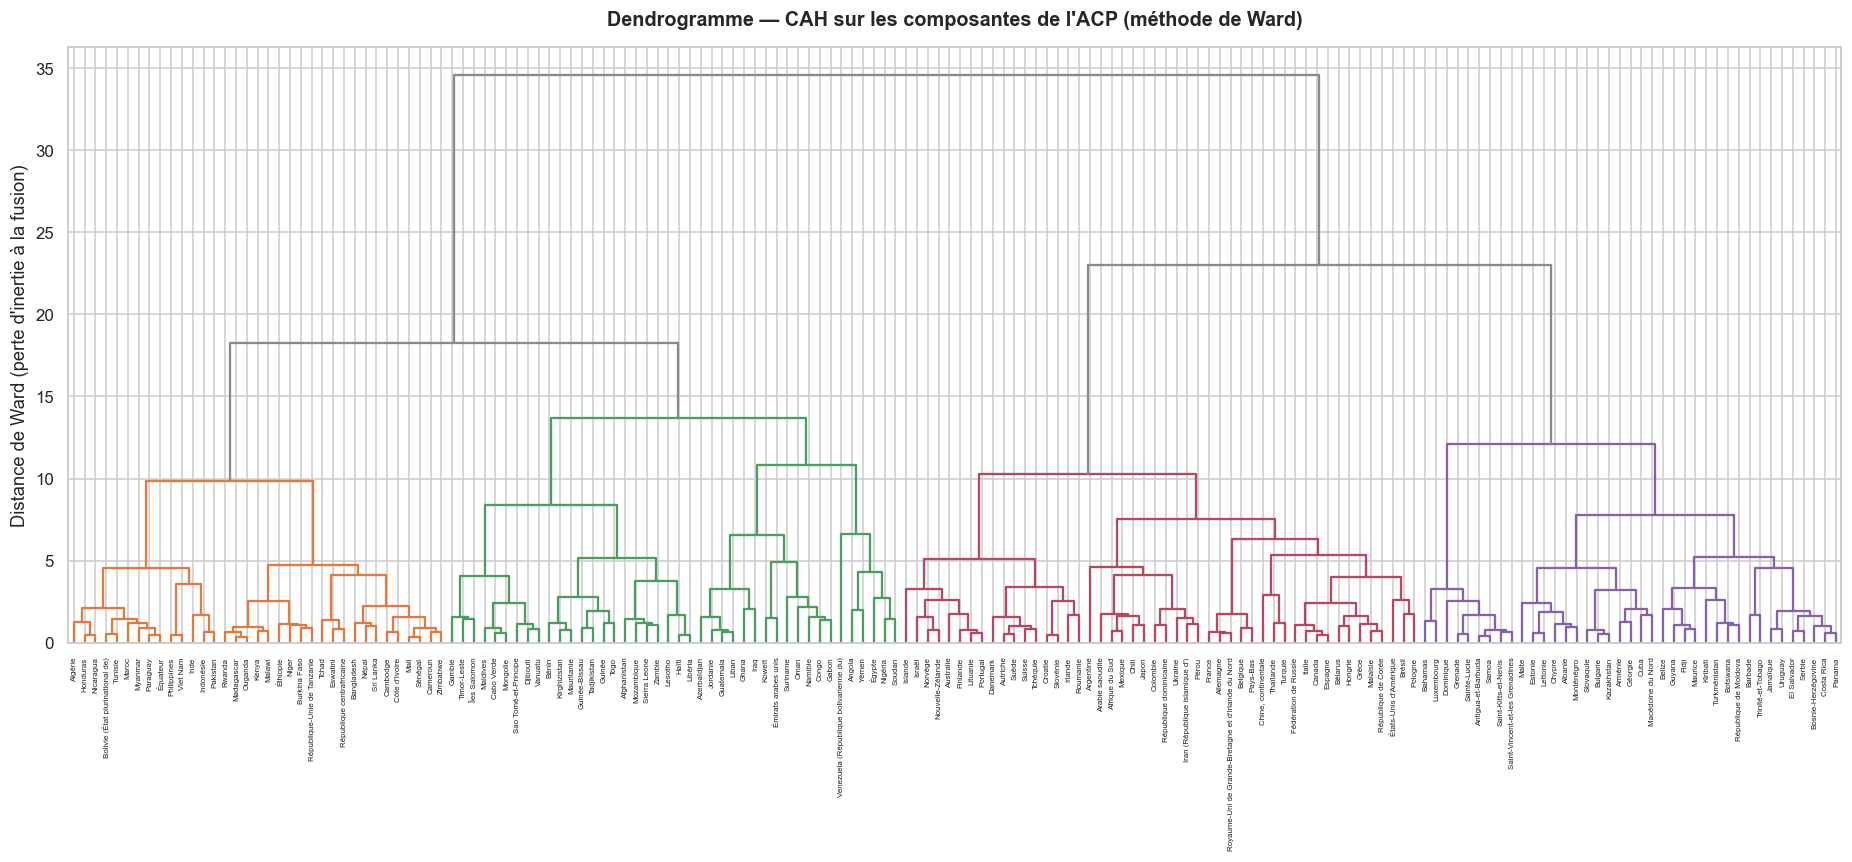

In [14]:
Z = linkage(coords_ret, method="ward")

fig, ax = plt.subplots(figsize=(17, 8))
dendrogram(Z, labels=PAYS, leaf_rotation=90, leaf_font_size=5.2,
           color_threshold=Z[-3, 2], ax=ax, above_threshold_color="#8A8A8A")
ax.set_title("Dendrogramme — CAH sur les composantes de l'ACP (méthode de Ward)", pad=14)
ax.set_ylabel("Distance de Ward (perte d'inertie à la fusion)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Ce que ce graphique montre :**

Chaque feuille en bas est un pays. Deux branches qui se rejoignent signifient une fusion,
et la **hauteur du trait horizontal** mesure le coût de cette fusion : plus il est haut, plus les
deux groupes fusionnés étaient différents.

Couper le dendrogramme par une ligne horizontale donne une partition. Le nombre de branches
traversées est le nombre de clusters obtenus.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">8.2 - Où couper l'arbre ?</h3>
</div>

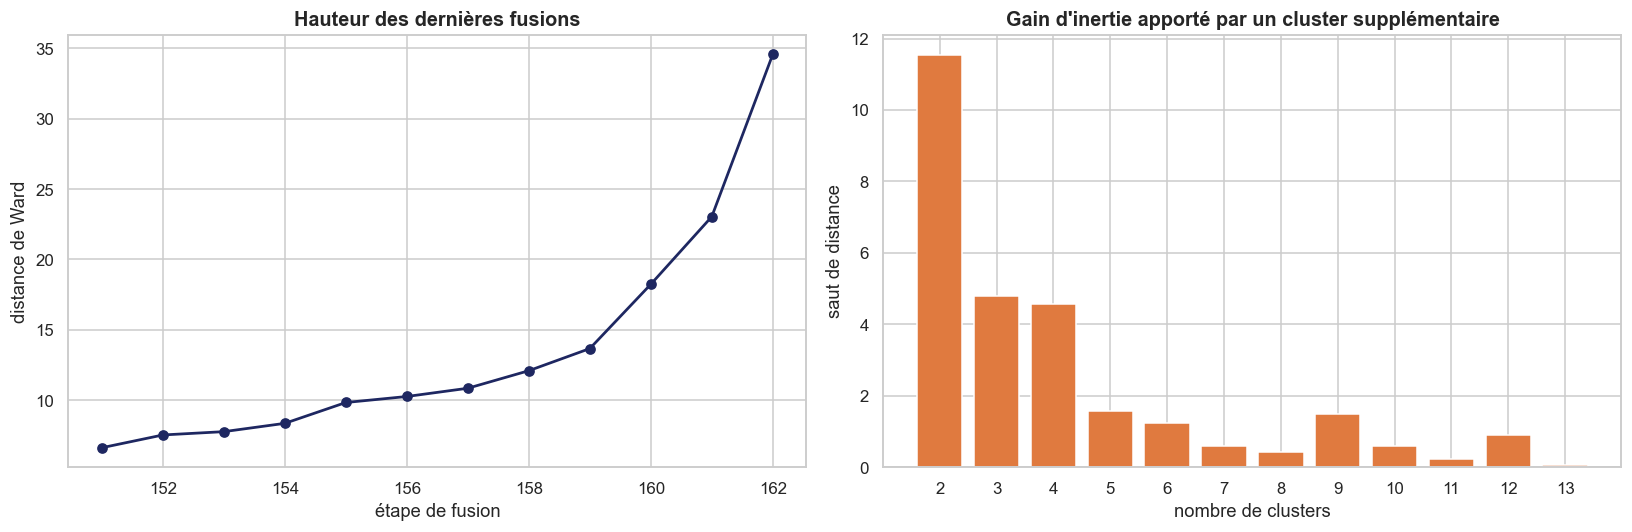

In [15]:
distances = Z[:, 2]
sauts = np.diff(distances)
derniers = 12

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(range(len(distances) - derniers, len(distances)),
             distances[-derniers:], "o-", color=NAVY, lw=1.8)
axes[0].set_title("Hauteur des dernières fusions")
axes[0].set_xlabel("étape de fusion"); axes[0].set_ylabel("distance de Ward")

k_range = np.arange(2, derniers + 2)
gains = sauts[-derniers:][::-1]
axes[1].bar(k_range[:len(gains)], gains, color="#E07A3F", edgecolor="white")
axes[1].set_title("Gain d'inertie apporté par un cluster supplémentaire")
axes[1].set_xlabel("nombre de clusters"); axes[1].set_ylabel("saut de distance")
axes[1].set_xticks(k_range[:len(gains)])
plt.tight_layout()
plt.show()

**Ce que ce graphique montre :**

À gauche, la hauteur des dernières fusions. À droite, le gain d'inertie qu'apporte
chaque cluster supplémentaire. Un **saut important** signifie que passer à ce nombre de clusters
évite une fusion coûteuse : les plus grands sauts indiquent les découpages naturels.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">8.3 - Essais sur plusieurs valeurs de k</h3>
</div>

In [16]:
resultats_cah = []
for k in range(2, 9):
    lab = fcluster(Z, k, criterion="maxclust")
    tailles = pd.Series(lab).value_counts().sort_index().tolist()
    resultats_cah.append({
        "k": k,
        "silhouette": round(silhouette_score(coords_ret, lab), 3),
        "taille_min": min(tailles), "taille_max": max(tailles),
        "répartition": tailles,
    })

titre("ESSAIS DE DÉCOUPAGE — CAH")
display(pd.DataFrame(resultats_cah))

ESSAIS DE DÉCOUPAGE — CAH


,k,silhouette,taille_min,taille_max,répartition
0,2,0.29,77,87,"[77, 87]"
1,3,0.24,39,77,"[77, 48, 39]"
2,4,0.24,35,48,"[35, 42, 48, 39]"
3,5,0.25,19,48,"[35, 23, 19, 48, 39]"
4,6,0.24,9,48,"[35, 23, 19, 48, 9, 30]"
5,7,0.25,6,48,"[35, 23, 13, 6, 48, 9, 30]"
6,8,0.22,6,35,"[35, 23, 13, 6, 17, 31, 9, 30]"


**Analyse et conclusion :**

Le coefficient de silhouette mesure la qualité d'une partition : proche de 1, les clusters
sont denses et bien séparés ; proche de 0, ils se chevauchent ; négatif, des individus sont mal classés.

Ici il reste compris entre 0,22 et 0,29 quelle que soit la valeur de k. **La structure est donc
faible** — les pays forment un continuum de développement plutôt que des groupes naturellement
séparés. Ce point est repris dans les limites de l'étude.

On écarte par ailleurs les partitions produisant des clusters de un ou deux pays : statistiquement
recevables, elles sont inutilisables pour une décision commerciale.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">8.4 - Partition CAH retenue</h3>
</div>

In [17]:
K = 4          # décision argumentée en étape 9

df["cluster_cah"] = fcluster(Z, K, criterion="maxclust")

titre(f"PARTITION CAH RETENUE : K = {K}")
print(f"Silhouette : {silhouette_score(coords_ret, df['cluster_cah']):.3f}\n")
display(df["cluster_cah"].value_counts().sort_index()
          .rename("nb_pays").to_frame()
          .assign(**{"%": lambda t: (t["nb_pays"] / len(df) * 100).round(1)}))

PARTITION CAH RETENUE : K = 4
Silhouette : 0.239



,nb_pays,%
cluster_cah,,
1,35,21.30
2,42,25.60
3,48,29.30
4,39,23.80


<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 9 - K-means — recherche du nombre optimal de clusters</h2>
</div>

Le k-means fonctionne différemment de la CAH : on fixe **à l'avance** le nombre de clusters,
l'algorithme place les centres au hasard, affecte chaque pays au centre le plus proche, recalcule
les centres, et recommence jusqu'à stabilisation.

Deux méthodes convergentes pour choisir `k` :

+ **la méthode du coude** — l'inertie intra-cluster décroît toujours, mais on cherche le point où
  elle cesse de décroître fortement ;
+ **le coefficient de silhouette** — on cherche son maximum.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">9.1 - Essais sur plusieurs valeurs de k</h3>
</div>

In [18]:
inerties, silhouettes, resultats_km = [], [], []
for k in range(2, 11):
    km_ = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lab = km_.fit_predict(coords_ret)
    sil = silhouette_score(coords_ret, lab)
    inerties.append(km_.inertia_); silhouettes.append(sil)
    tailles = pd.Series(lab).value_counts().sort_index().tolist()
    resultats_km.append({"k": k, "inertie": round(km_.inertia_, 1),
                         "silhouette": round(sil, 3),
                         "taille_min": min(tailles), "répartition": tailles})

titre("ESSAIS SUR PLUSIEURS VALEURS DE K — K-MEANS")
display(pd.DataFrame(resultats_km))

ESSAIS SUR PLUSIEURS VALEURS DE K — K-MEANS


,k,inertie,silhouette,taille_min,répartition
0,2,"1,184.20",0.32,82,"[82, 82]"
1,3,883.70,0.32,44,"[61, 59, 44]"
2,4,758.80,0.28,27,"[52, 51, 34, 27]"
3,5,648.50,0.29,23,"[47, 32, 37, 23, 25]"
4,6,579.90,0.29,5,"[5, 35, 23, 24, 30, 47]"
5,7,519.10,0.28,5,"[5, 28, 24, 30, 13, 34, 30]"
6,8,478.60,0.27,8,"[8, 28, 26, 31, 13, 26, 13, 19]"
7,9,448.20,0.25,6,"[18, 24, 28, 6, 25, 14, 25, 10, 14]"
8,10,422.10,0.26,5,"[24, 30, 14, 23, 11, 18, 18, 5, 12, 9]"


<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">9.2 - Méthode du coude et coefficient de silhouette</h3>
</div>

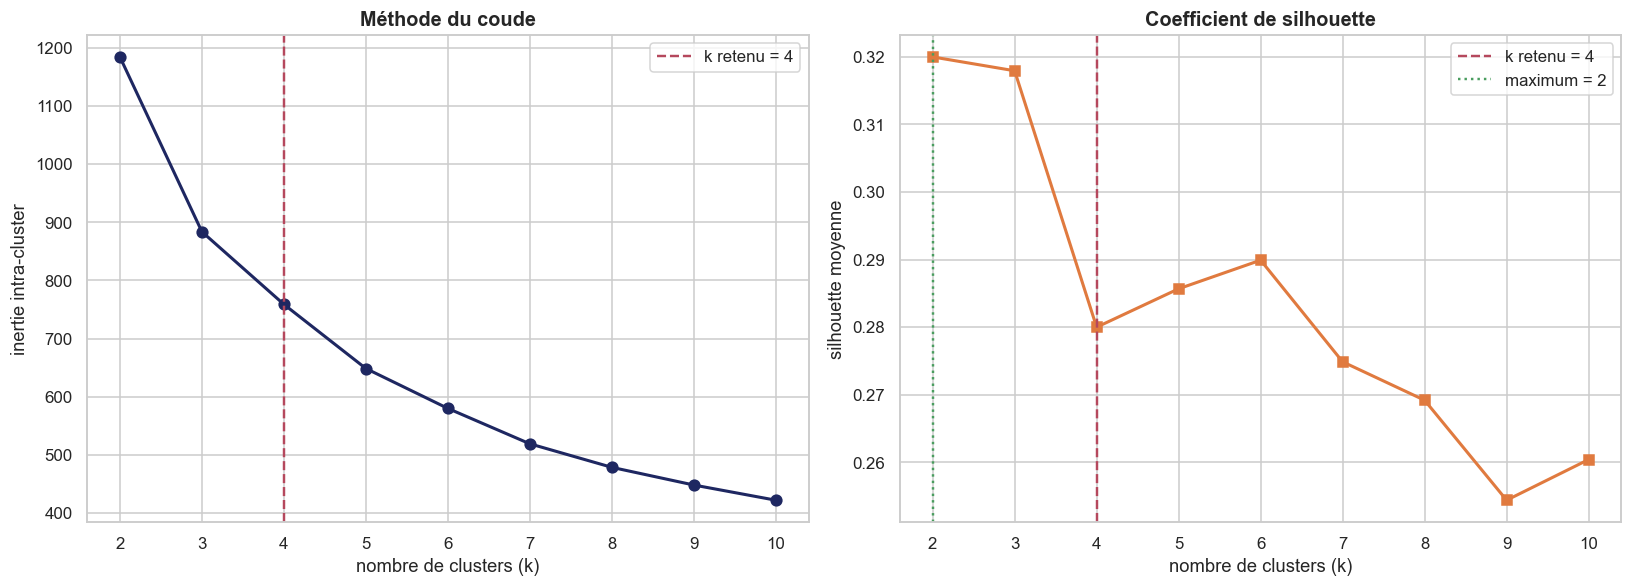

Silhouette maximale       : k = 2 (0.320)
Nombre de clusters retenu : k = 4


In [19]:
ks = list(range(2, 11))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(ks, inerties, "o-", color=NAVY, lw=2, ms=7)
axes[0].axvline(K, color="#B5485D", ls="--", lw=1.6, label=f"k retenu = {K}")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("nombre de clusters (k)"); axes[0].set_ylabel("inertie intra-cluster")
axes[0].set_xticks(ks); axes[0].legend()

axes[1].plot(ks, silhouettes, "s-", color="#E07A3F", lw=2, ms=7)
axes[1].axvline(K, color="#B5485D", ls="--", lw=1.6, label=f"k retenu = {K}")
best = ks[int(np.argmax(silhouettes))]
axes[1].axvline(best, color="#4A9D5F", ls=":", lw=1.6, label=f"maximum = {best}")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("nombre de clusters (k)"); axes[1].set_ylabel("silhouette moyenne")
axes[1].set_xticks(ks); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Silhouette maximale       : k = {best} ({max(silhouettes):.3f})")
print(f"Nombre de clusters retenu : k = {K}")

**Analyse et conclusion :**

Le coude apparaît autour de k = 3 ou 4, et la silhouette est maximale à k = 2 puis reste
très stable jusqu'à k = 6. **Les critères statistiques ne tranchent donc pas** : ils indiquent une
plage, pas une valeur unique.

**Nous retenons k = 4, en ajoutant un critère métier.** Deux clusters ne feraient que séparer les
pays riches des pays pauvres — une évidence sans valeur commerciale. Quatre segments constituent un
découpage qu'un comité de direction peut comprendre et sur lequel il peut arbitrer, tout en restant
assez fin pour distinguer les producteurs des importateurs.

Un critère purement statistique n'est pas suffisant pour cette décision : la lisibilité par le
destinataire de l'analyse compte autant que l'optimum mathématique. C'est un arbitrage assumé
et argumenté.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">9.3 - Partition retenue et diagramme de silhouette</h3>
</div>

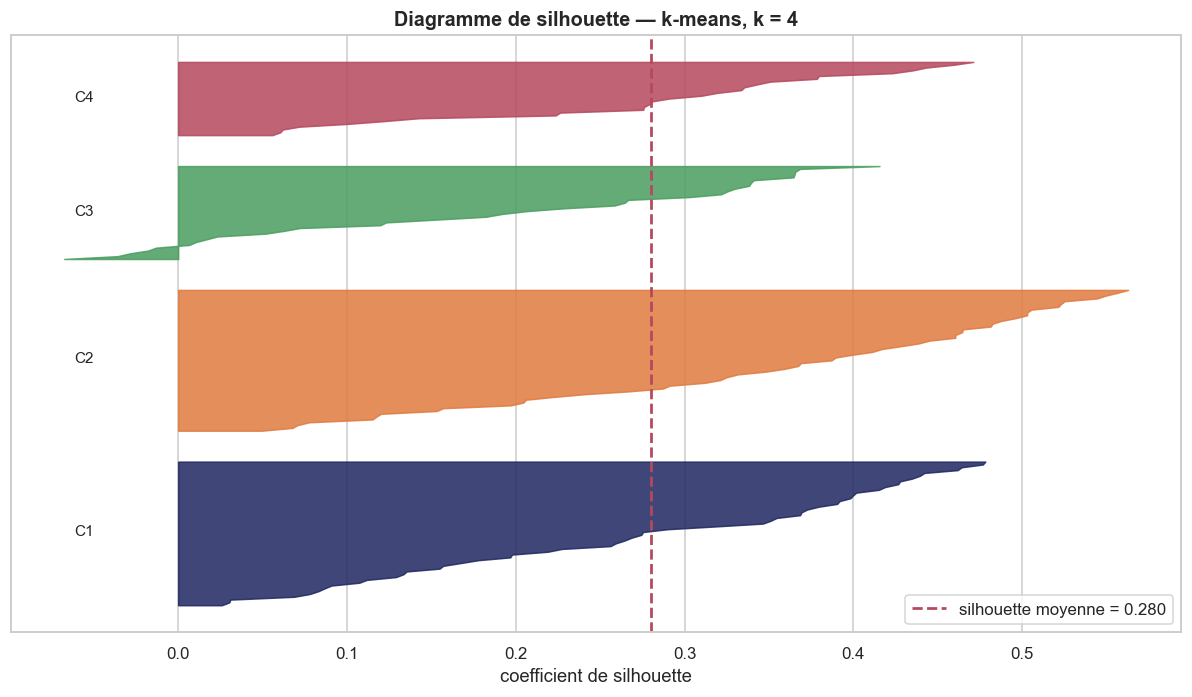

Pays au coefficient négatif (mal classés) : 5 sur 164


In [20]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
df["cluster_kmeans"] = km.fit_predict(coords_ret) + 1     # numérotation à partir de 1

sil_vals = silhouette_samples(coords_ret, df["cluster_kmeans"])
sil_moy = sil_vals.mean()

fig, ax = plt.subplots(figsize=(11, 6.5))
y_bas = 10
for i, c in enumerate(sorted(df["cluster_kmeans"].unique())):
    vals = np.sort(sil_vals[df["cluster_kmeans"] == c])
    y_haut = y_bas + len(vals)
    ax.fill_betweenx(np.arange(y_bas, y_haut), 0, vals,
                     color=PALETTE[i % len(PALETTE)], alpha=.85)
    ax.text(-0.05, y_bas + len(vals) / 2, f"C{c}", ha="right", va="center", fontsize=10)
    y_bas = y_haut + 10
ax.axvline(sil_moy, color="#B5485D", ls="--", lw=1.8,
           label=f"silhouette moyenne = {sil_moy:.3f}")
ax.set_xlabel("coefficient de silhouette"); ax.set_yticks([])
ax.set_title(f"Diagramme de silhouette — k-means, k = {K}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pays au coefficient négatif (mal classés) : {(sil_vals < 0).sum()} sur {len(df)}")

**Ce que ce graphique montre :**

Chaque bande horizontale est un pays, sa longueur son coefficient de silhouette.
Les clusters sont empilés. Un cluster « large et long » est dense et bien séparé ; un cluster
avec des bandes courtes ou négatives contient des pays mal classés, situés à la frontière de
deux groupes.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 10 - Comparaison des deux méthodes</h2>
</div>

Les deux algorithmes ne fonctionnent pas de la même façon : il serait anormal qu'ils donnent
exactement la même partition. Ce qui compte est de mesurer **à quel point ils convergent**.

L'**indice de Rand ajusté (ARI)** quantifie l'accord entre deux partitions :

| ARI | Interprétation |
|---|---|
| 1,00 | partitions identiques |
| supérieur à 0,75 | accord très fort |
| 0,50 à 0,75 | accord substantiel |
| environ 0 | accord équivalent au hasard |

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">10.1 - Table de contingence</h3>
</div>

In [21]:
ari = adjusted_rand_score(df["cluster_cah"], df["cluster_kmeans"])

cont = pd.crosstab(df["cluster_cah"], df["cluster_kmeans"],
                   rownames=["CAH"], colnames=["K-means"],
                   margins=True, margins_name="Total")

titre("TABLE DE CONTINGENCE CAH x K-MEANS")
display(cont)

accord = (cont.iloc[:-1, :-1].max(axis=1).sum() / len(df)) * 100
print(f"\nIndice de Rand ajusté : {ari:.3f}")
print(f"Taux d'accord (appariement optimal des étiquettes) : {accord:.1f} %")

TABLE DE CONTINGENCE CAH x K-MEANS


K-means,1,2,3,4,Total
CAH,,,,,
1,35,0,0,0,35
2,14,1,2,25,42
3,0,46,2,0,48
4,3,4,30,2,39
Total,52,51,34,27,164



Indice de Rand ajusté : 0.626
Taux d'accord (appariement optimal des étiquettes) : 82.9 %


**Analyse et conclusion :**

L'indice de Rand ajusté atteint **0,63**, soit un accord **substantiel** entre les deux
méthodes. Chaque cluster CAH correspond très majoritairement à un cluster k-means : la diagonale
de la table concentre l'essentiel des effectifs.

Cette convergence **valide la structure trouvée**. Si deux algorithmes fondés sur des principes
différents identifient les mêmes groupes, c'est que ces groupes existent réellement dans les
données et ne sont pas un artefact de méthode.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">10.2 - Visualisation côte à côte</h3>
</div>

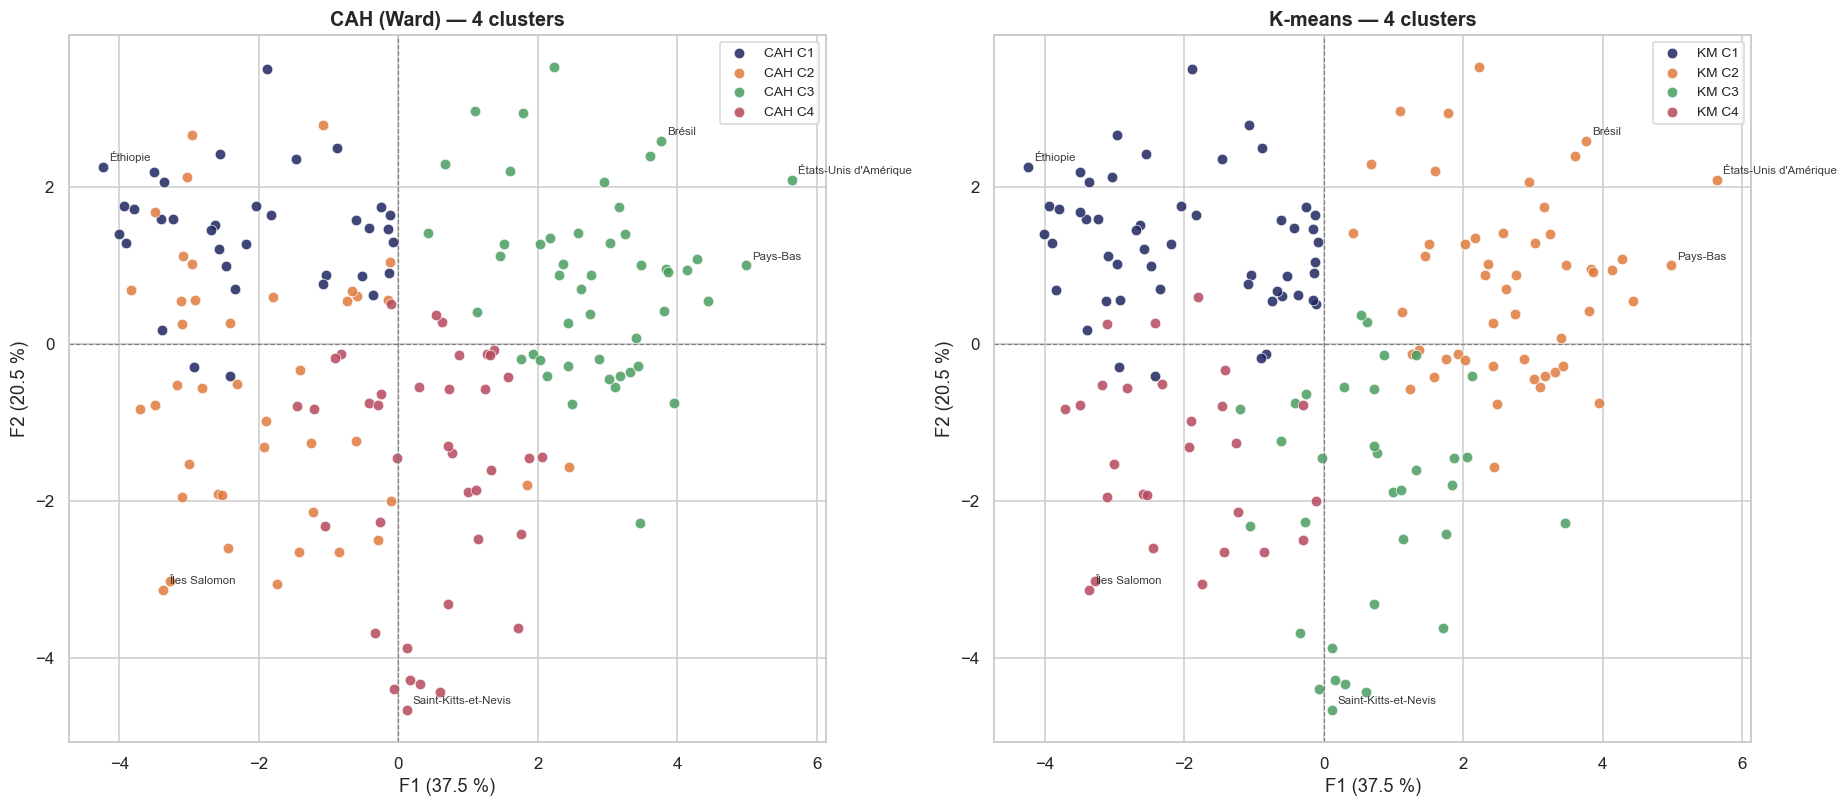

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
projeter(0, 1, couleurs=df["cluster_cah"].tolist(), legende="CAH C",
         titre_g=f"CAH (Ward) — {K} clusters", ax=axes[0], annoter=6)
projeter(0, 1, couleurs=df["cluster_kmeans"].tolist(), legende="KM C",
         titre_g=f"K-means — {K} clusters", ax=axes[1], annoter=6)
plt.tight_layout()
plt.show()

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">10.3 - Les pays sur lesquels les deux méthodes divergent</h3>
</div>

In [23]:
# Appariement : à chaque cluster CAH on associe le cluster k-means dominant
corresp = cont.iloc[:-1, :-1].idxmax(axis=1).to_dict()
df["_cah_apparie"] = df["cluster_cah"].map(corresp)

divergents = (df.loc[df["_cah_apparie"] != df["cluster_kmeans"],
                     ["pays", "continent", "cluster_cah", "_cah_apparie", "cluster_kmeans"]]
                .rename(columns={"_cah_apparie": "kmeans_attendu"}))

titre("PAYS CLASSÉS DIFFÉREMMENT PAR LES DEUX MÉTHODES")
print(f"{len(divergents)} pays sur {len(df)} ({len(divergents)/len(df)*100:.1f} %)")
print("\nAppariement des étiquettes :")
for cah, km_ in corresp.items():
    print(f"   CAH {cah}  ->  K-means {km_}")
print()
display(divergents.reset_index(drop=True))

df = df.drop(columns="_cah_apparie")

PAYS CLASSÉS DIFFÉREMMENT PAR LES DEUX MÉTHODES
28 pays sur 164 (17.1 %)

Appariement des étiquettes :
   CAH 1  ->  K-means 1
   CAH 2  ->  K-means 4
   CAH 3  ->  K-means 2
   CAH 4  ->  K-means 3



,pays,continent,cluster_cah,kmeans_attendu,cluster_kmeans
0,Afghanistan,Asie,2,4,1
1,Azerbaïdjan,Asie,2,4,1
2,Botswana,Afrique,4,3,4
3,Bulgarie,Europe,4,3,2
4,Costa Rica,Amériques,4,3,2
5,El Salvador,Amériques,4,3,1
6,Guatemala,Amériques,2,4,1
7,Géorgie,Asie,4,3,4
8,Islande,Europe,3,2,3
9,Jordanie,Asie,2,4,1


### Réponse de soutenance — *« Les deux méthodes ont-elles donné les mêmes résultats ? »*

Les partitions sont **largement convergentes mais pas identiques**, et c'est attendu :

| | CAH | K-means |
|---|---|---|
| Principe | fusions successives, ascendant | optimisation itérative autour de centres |
| Nombre de clusters | décidé **après** coup, en coupant l'arbre | fixé **avant** l'exécution |
| Réversibilité | une fusion n'est jamais remise en cause | un pays peut changer de groupe à chaque itération |
| Stabilité | déterministe | dépend de l'initialisation, d'où `random_state` |

**Pourquoi elles divergent** : la CAH est *gloutonne*. Une fusion précoce sous-optimale ne peut plus
être corrigée par la suite. Le k-means, lui, réaffecte librement les individus à chaque tour, ce qui
lui permet de rattraper une mauvaise affectation initiale.

**Les pays sur lesquels elles divergent sont les pays frontières** : ceux situés entre deux groupes,
dont le coefficient de silhouette est faible. Leur classement est fragile — c'est une information
utile en soi, à signaler dans toute recommandation commerciale.

**Conclusion** : la convergence des deux méthodes valide la segmentation. Si elles avaient donné des
résultats opposés, il aurait fallu douter de la structure trouvée.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 11 - Banc d'essai : pourquoi ces deux méthodes et pas d'autres</h2>
</div>

Le cahier des charges impose deux méthodes de classification. Encore faut-il justifier
**lesquelles**, et pouvoir expliquer pourquoi les autres ont été écartées.

Plutôt que de s'appuyer sur des arguments théoriques, on **teste** les principales familles
d'algorithmes sur les mêmes données — les quatre composantes de l'ACP — et on compare les résultats.

| Famille | Principe | Ce qu'elle suppose des données |
|---|---|---|
| **K-means** | minimise la distance aux centres, par itérations | clusters globulaires, de taille comparable |
| **CAH** | fusionne les groupes les plus proches, de proche en proche | dépend du critère de liaison choisi |
| **Mélange gaussien** | modélise les données comme un mélange de lois normales | clusters ellipsoïdaux, appartenance probabiliste |
| **DBSCAN** | agrège les points par densité, isole le reste comme du bruit | zones denses séparées par des zones vides |
| **Spectral** | partitionne un graphe de voisinage | clusters de forme quelconque, éventuellement non convexes |
| **BIRCH** | construit un arbre de résumés, puis agrège | très grands volumes de données |
| **Mean-Shift** | recherche les modes de densité | nombre de clusters inconnu a priori |

In [24]:
# =============================================================================
# 11. BANC D'ESSAI DES MÉTHODES DE CLUSTERING
# =============================================================================

from sklearn.cluster import DBSCAN, SpectralClustering, Birch, MeanShift
from sklearn.mixture import GaussianMixture

# CLUSTER n'est défini qu'à l'étape 13 : on référence ici la colonne directement.
reference = df["cluster_kmeans"].values      # partition retenue, pour comparaison


def evaluer(nom, labels, famille):
    """Évalue une partition : nombre de clusters, bruit, silhouette, accord avec la référence."""
    labels = np.asarray(labels)
    valides = labels >= 0                       # -1 = bruit chez DBSCAN
    k = len(set(labels[valides]))
    sil = (silhouette_score(coords_ret[valides], labels[valides])
           if k > 1 and valides.sum() > k else np.nan)
    tailles = sorted(pd.Series(labels[valides]).value_counts().tolist(), reverse=True)
    return {"famille": famille, "méthode": nom, "k": k,
            "pays_non_classés": int((~valides).sum()),
            "silhouette": round(sil, 3) if sil == sil else None,
            "ARI_vs_retenu": round(adjusted_rand_score(reference, labels), 3),
            "tailles": str(tailles[:6])}


essais = []

# --- Les deux méthodes retenues ---
essais.append(evaluer("K-means (retenu)", reference, "K-means"))
essais.append(evaluer("CAH Ward (retenu)", fcluster(Z, K, "maxclust"), "CAH"))

# --- Autres critères de liaison pour la CAH ---
for crit in ["complete", "average", "single"]:
    essais.append(evaluer(f"CAH {crit}", fcluster(linkage(coords_ret, crit), K, "maxclust"), "CAH"))

# --- Mélange gaussien, trois formes de covariance ---
for cov in ["full", "tied", "diag"]:
    essais.append(evaluer(f"Mélange gaussien ({cov})",
                          GaussianMixture(K, covariance_type=cov,
                                          random_state=RANDOM_STATE).fit_predict(coords_ret),
                          "Mélange gaussien"))

# --- DBSCAN : balayage du rayon de voisinage ---
for eps in [0.8, 1.2, 1.6, 2.0]:
    essais.append(evaluer(f"DBSCAN (eps={eps})",
                          DBSCAN(eps=eps, min_samples=5).fit_predict(coords_ret), "DBSCAN"))

# --- Autres approches ---
essais.append(evaluer("Spectral",
                      SpectralClustering(K, random_state=RANDOM_STATE,
                                         affinity="nearest_neighbors",
                                         n_neighbors=10).fit_predict(coords_ret), "Spectral"))
essais.append(evaluer("BIRCH", Birch(n_clusters=K).fit_predict(coords_ret), "BIRCH"))
essais.append(evaluer("Mean-Shift", MeanShift().fit_predict(coords_ret), "Mean-Shift"))

banc = pd.DataFrame(essais)

titre("COMPARAISON DE 7 FAMILLES D'ALGORITHMES SUR LES MÊMES DONNÉES")
display(banc)

COMPARAISON DE 7 FAMILLES D'ALGORITHMES SUR LES MÊMES DONNÉES


,famille,méthode,k,pays_non_classés,silhouette,ARI_vs_retenu,tailles
0,K-means,K-means (retenu),4,0,0.28,1.00,"[52, 51, 34, 27]"
1,CAH,CAH Ward (retenu),4,0,0.24,0.63,"[48, 42, 39, 35]"
2,CAH,CAH complete,4,0,0.24,0.44,"[84, 40, 39, 1]"
3,CAH,CAH average,4,0,0.28,0.39,"[80, 44, 39, 1]"
4,CAH,CAH single,4,0,0.01,-0.01,"[161, 1, 1, 1]"
5,Mélange gaussien,Mélange gaussien (full),4,0,0.22,0.27,"[89, 34, 29, 12]"
6,Mélange gaussien,Mélange gaussien (tied),4,0,0.23,0.44,"[52, 50, 44, 18]"
7,Mélange gaussien,Mélange gaussien (diag),4,0,0.23,0.58,"[58, 50, 34, 22]"
8,DBSCAN,DBSCAN (eps=0.8),2,154,0.90,0.01,"[5, 5]"
9,DBSCAN,DBSCAN (eps=1.2),7,70,0.33,0.14,"[27, 26, 19, 7, 6, 5]"


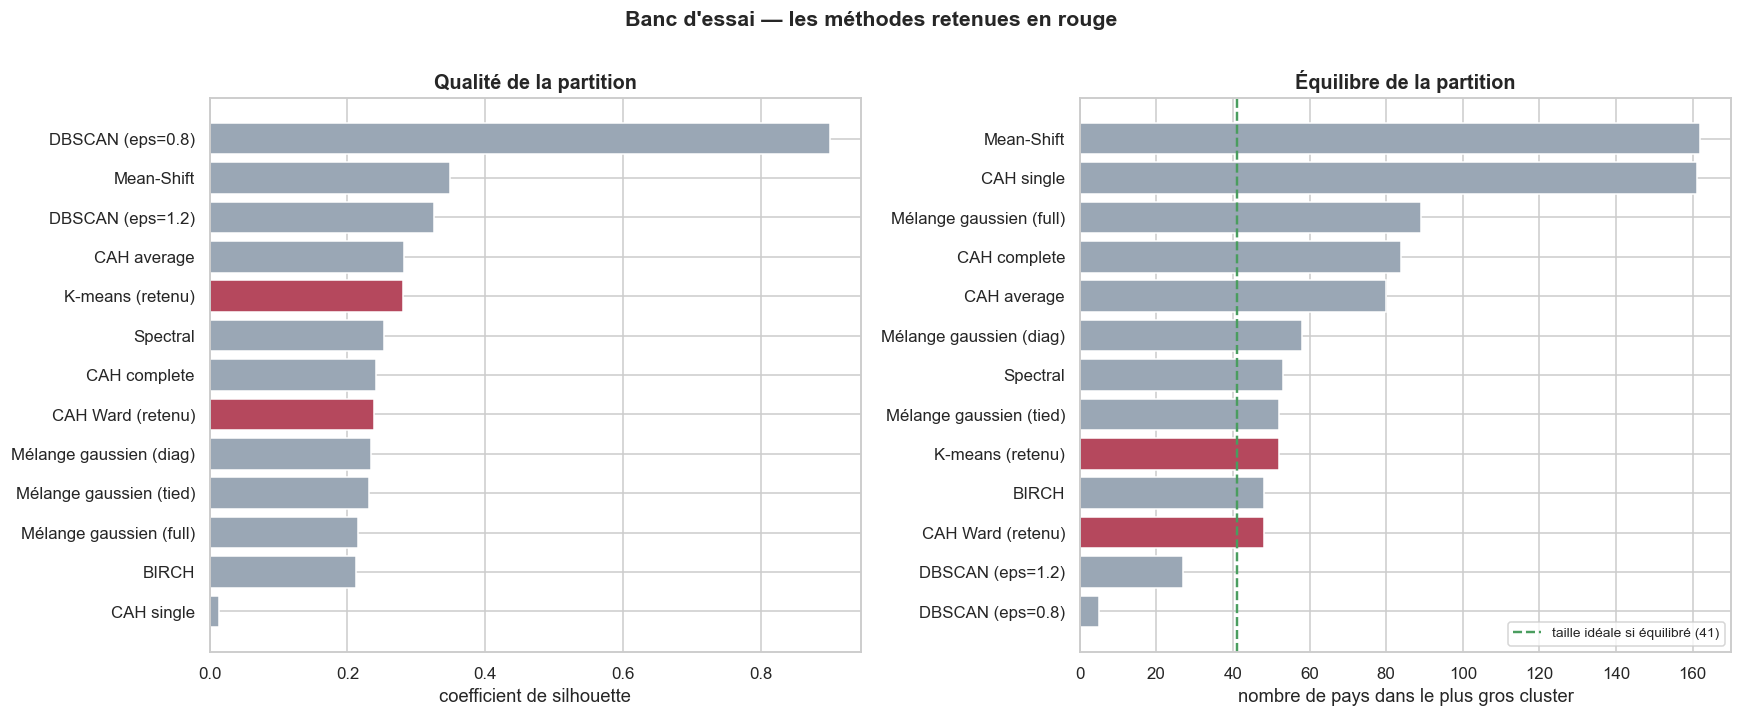

Une silhouette élevée ne suffit pas : une partition qui isole un seul pays
obtient un bon score tout en étant commercialement inutilisable.
Les deux critères doivent être lus ensemble.


In [25]:
# --- Lecture visuelle : silhouette et équilibre des clusters -----------------

exploitables = banc[banc["silhouette"].notna()].copy()
exploitables["taille_du_plus_gros"] = (
    exploitables["tailles"].str.strip("[]").str.split(",").str[0].astype(int))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

ordre = exploitables.sort_values("silhouette")
couleurs = ["#B5485D" if "retenu" in m else "#9AA7B5" for m in ordre["méthode"]]
axes[0].barh(ordre["méthode"], ordre["silhouette"], color=couleurs, edgecolor="white")
axes[0].set_xlabel("coefficient de silhouette")
axes[0].set_title("Qualité de la partition")

ordre2 = exploitables.sort_values("taille_du_plus_gros")
couleurs2 = ["#B5485D" if "retenu" in m else "#9AA7B5" for m in ordre2["méthode"]]
axes[1].barh(ordre2["méthode"], ordre2["taille_du_plus_gros"], color=couleurs2, edgecolor="white")
axes[1].axvline(len(df) / K, color="#4A9D5F", ls="--", lw=1.6,
                label=f"taille idéale si équilibré ({len(df)//K})")
axes[1].set_xlabel("nombre de pays dans le plus gros cluster")
axes[1].set_title("Équilibre de la partition")
axes[1].legend(fontsize=9)

fig.suptitle("Banc d'essai — les méthodes retenues en rouge", fontsize=14,
             fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

print("Une silhouette élevée ne suffit pas : une partition qui isole un seul pays")
print("obtient un bon score tout en étant commercialement inutilisable.")
print("Les deux critères doivent être lus ensemble.")

**Ce que ce graphique montre :**

À gauche, la qualité statistique de chaque partition (coefficient de silhouette). À droite, la
taille du plus gros cluster : c'est l'indicateur d'équilibre. Le trait vert marque la taille
qu'auraient les groupes si les pays étaient répartis équitablement.

Les deux méthodes retenues apparaissent en rouge.

**Analyse et conclusion :**

### Pourquoi le duo CAH + k-means

Le choix n'est pas « la meilleure méthode » dans l'absolu, mais **deux méthodes complémentaires**.

**La CAH en premier**, parce qu'elle ne présuppose pas le nombre de groupes : le dendrogramme le
*suggère*, on regarde où couper. C'est la phase d'exploration.

**Le k-means ensuite**, parce qu'il optimise. La CAH est gloutonne — une fusion précoce n'est
jamais remise en cause. Le k-means réaffecte librement les individus à chaque itération et corrige
les mauvaises affectations initiales. L'écart de silhouette entre les deux le confirme.

**Le critère de Ward plutôt qu'un autre** : c'est le seul de la famille CAH qui minimise la variance
intra-groupe, exactement l'objectif du k-means. Les deux partitions deviennent donc comparables —
sans cela, l'indice de Rand calculé à l'étape 10 n'aurait aucun sens.

### Pourquoi les autres méthodes ont été écartées

**CAH *single linkage* — l'effet de chaînage.** Elle place la quasi-totalité des pays dans un seul
cluster et laisse trois singletons. Sa silhouette tombe à un niveau proche du hasard. La méthode
fusionne dès que *deux points* sont proches : elle relie donc tout le monde de proche en proche le
long du continuum. C'est le contre-exemple pédagogique de ce banc d'essai.

**CAH *complete* et *average*.** Elles fonctionnent, mais produisent un **cluster d'un seul pays**.
Statistiquement recevable, commercialement inutilisable : on ne bâtit pas une stratégie d'export
sur un segment à un membre.

**DBSCAN — l'échec le plus instructif.** Quel que soit le rayon testé, aucune partition
exploitable : avec un rayon serré, l'immense majorité des pays est classée comme du **bruit** ;
avec un rayon large, tous les pays se retrouvent dans un cluster unique. Aucun réglage
intermédiaire ne convient.

**Ce n'est pas un défaut de l'algorithme, c'est une information sur les données.** DBSCAN cherche
des zones denses séparées par des zones vides. Or le développement économique est un **continuum** :
il n'existe pas de vallée de densité entre pays riches et pays pauvres, mais un dégradé continu.
Ce résultat converge avec le coefficient de silhouette modéré observé partout ailleurs.

**Mélange gaussien.** Plus souple que le k-means — clusters ellipsoïdaux, appartenance
probabiliste — mais silhouette inférieure et groupes déséquilibrés. Le gain théorique ne se
matérialise pas sur ces données.

**Spectral clustering.** Il fonctionne correctement, mais son intérêt réside dans la détection de
formes non convexes, en spirale ou en croissant. Nos clusters sont globulaires : aucun bénéfice, et
une perte réelle d'interprétabilité, les composantes spectrales n'ayant pas de sens métier.

**BIRCH.** Conçu pour des jeux de données trop volumineux pour tenir en mémoire. Avec 164 individus,
c'est un sur-dimensionnement sans contrepartie.

**Mean-Shift.** Sa fenêtre de densité, estimée automatiquement, est trop large pour un nuage aussi
compact : il ne distingue que deux groupes, dont un contient la quasi-totalité des pays.

### Ce que ce banc d'essai apporte à l'analyse

Au-delà de la justification du choix, il **confirme un résultat** : aucune méthode, quelle que soit
sa famille, ne trouve de structure nettement séparée dans ces données. Les silhouettes plafonnent
toutes au même niveau, et la méthode fondée sur la densité échoue complètement.

La segmentation en quatre groupes reste un **outil de décision valable**, mais les frontières entre
groupes sont conventionnelles et non naturelles. C'est une limite à annoncer, pas à dissimuler.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 12 - Données brutes ou données ACP pour le clustering ?</h2>
</div>

Question explicitement posée dans la grille d'évaluation. On y répond **en testant**, plutôt
qu'en argumentant dans le vide.

In [26]:
km_brut = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
lab_brut = km_brut.fit_predict(X_scaled) + 1

comparaison = pd.DataFrame([
    {"jeu de données": f"Composantes ACP ({N_AXES} axes)", "dimensions": N_AXES,
     "silhouette": round(silhouette_score(coords_ret, df["cluster_kmeans"]), 3),
     "inertie": round(km.inertia_, 1)},
    {"jeu de données": f"Variables centrées-réduites ({len(VARS)} variables)",
     "dimensions": len(VARS),
     "silhouette": round(silhouette_score(X_scaled, lab_brut), 3),
     "inertie": round(km_brut.inertia_, 1)},
])

titre("COMPARAISON DES DEUX APPROCHES")
display(comparaison)

ari_bp = adjusted_rand_score(lab_brut, df["cluster_kmeans"])
print(f"\nIndice de Rand ajusté entre les deux partitions : {ari_bp:.3f}")
print(f"Pays classés différemment : {(lab_brut != df['cluster_kmeans']).sum()} sur {len(df)}")

COMPARAISON DES DEUX APPROCHES


,jeu de données,dimensions,silhouette,inertie
0,Composantes ACP (4 axes),4,0.28,758.80
1,Variables centrées-réduites (15 variables),15,0.20,"1,356.70"



Indice de Rand ajusté entre les deux partitions : 0.969
Pays classés différemment : 137 sur 164


### Réponse — *« Faut-il utiliser les données réelles ou celles de l'ACP ? »*

**Nous avons retenu les composantes de l'ACP.** Trois arguments :

1. **L'ACP décorrèle.** Nos variables d'origine sont fortement corrélées entre elles. Le k-means
   s'appuie sur la distance euclidienne, qui compte alors plusieurs fois la même information : trois
   variables mesurant la richesse pèsent triple. Les composantes de l'ACP sont orthogonales par
   construction, donc chaque dimension apporte une information nouvelle.
2. **L'ACP débruite.** Les derniers axes ne portent presque que du bruit de mesure. Les écarter
   améliore la stabilité de la partition.
3. **L'interprétation est plus simple.** Les clusters se lisent directement sur le plan factoriel,
   avec des axes qu'on a nommés.

**La limite** : on perd la part d'information portée par les axes écartés — environ 25 % ici.
C'est acceptable, les quatre axes retenus couvrant les trois quarts de la variance.

**Le test ci-dessus le confirme** : les deux approches produisent des partitions proches. La
réduction de dimension n'a donc pas déformé la structure des données. Le choix de l'ACP est un gain
de lisibilité sans perte de fond.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 13 - Caractérisation des clusters</h2>
</div>

Un numéro de cluster ne veut rien dire pour un comité de direction. Il faut décrire chaque
groupe **en langage métier** et lui donner un nom.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">13.1 - Profil moyen de chaque cluster</h3>
</div>

In [27]:
CLUSTER = "cluster_kmeans"      # partition de référence pour la suite

VARS_PROFIL = ["population", "dispo_volaille_kg", "production_volaille",
               "import_volaille", "export_volaille", "pib_habitant",
               "croissance_pib", "pop_urbaine_pct", "inflation",
               "taux_dependance_import", "taux_autosuffisance",
               "croissance_pop_2010_2018", "part_proteines_animales",
               "proteines_animales", "dispo_kcal_totale"]

profil = df.groupby(CLUSTER)[VARS_PROFIL].mean().round(1)
profil.insert(0, "nb_pays", df[CLUSTER].value_counts().sort_index())
profil.insert(1, "population_totale", df.groupby(CLUSTER)["population"].sum().round(0))

titre("PROFIL MOYEN DE CHAQUE CLUSTER")
display(profil.T)

PROFIL MOYEN DE CHAQUE CLUSTER


cluster_kmeans,1,2,3,4
nb_pays,52.00,51.00,34.00,27.00
population_totale,"3,436,207.00","3,582,714.00","64,536.00","188,826.00"
population,"66,080.90","70,249.30","1,898.10","6,993.60"
dispo_volaille_kg,8.80,27.50,33.20,9.90
production_volaille,347.70,"1,993.40",30.30,12.40
import_volaille,22.90,201.30,25.90,65.40
export_volaille,0.90,333.90,1.80,1.20
pib_habitant,"2,415.90","26,724.90","19,274.90","3,429.30"
croissance_pib,3.90,3.20,2.50,3.20
pop_urbaine_pct,44.40,75.10,60.10,52.80


<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">13.2 - Signature de chaque cluster</h3>
</div>

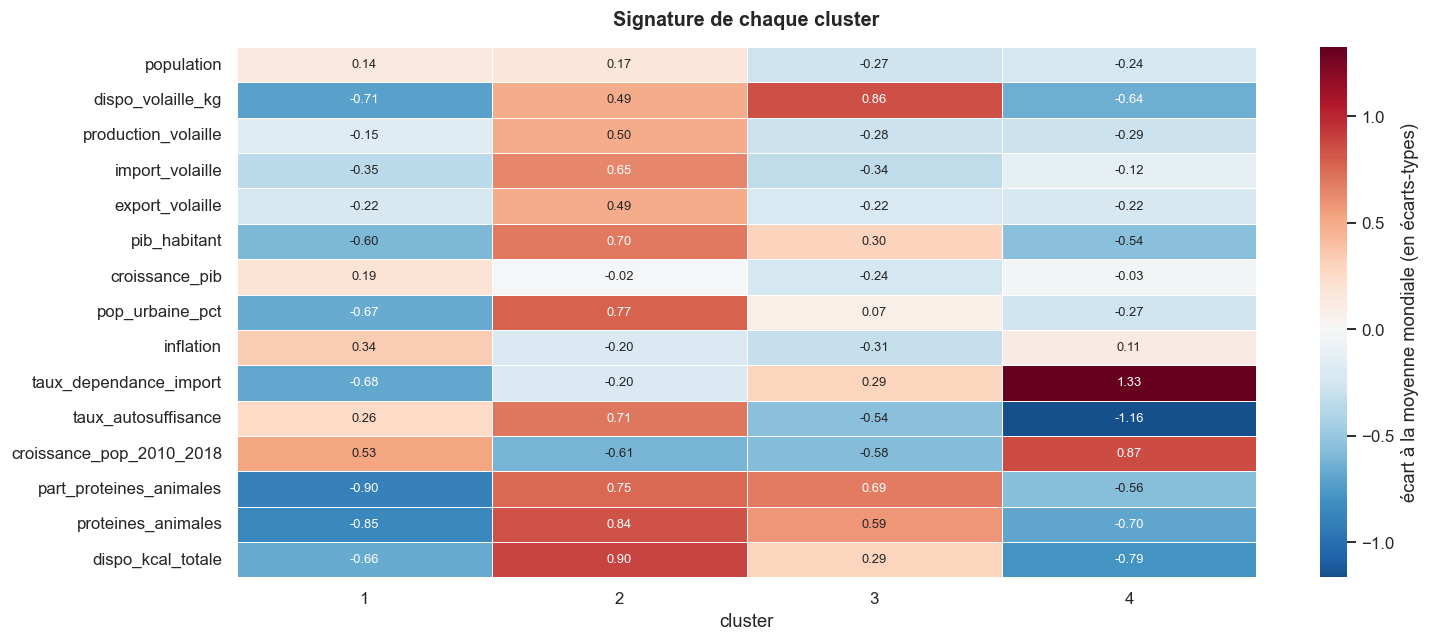

In [28]:
moy_monde = df[VARS_PROFIL].mean()
ecarts = (df.groupby(CLUSTER)[VARS_PROFIL].mean() - moy_monde) / df[VARS_PROFIL].std()

plt.figure(figsize=(14, 6))
sns.heatmap(ecarts.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5,
            annot_kws={"size": 8.5},
            cbar_kws={"label": "écart à la moyenne mondiale (en écarts-types)"})
plt.title("Signature de chaque cluster", pad=14)
plt.xlabel("cluster"); plt.ylabel("")
plt.tight_layout()
plt.show()

**Ce que ce graphique montre :**

Chaque colonne est un cluster, chaque ligne une variable. La couleur donne l'écart à la
moyenne mondiale, exprimé en écarts-types : **rouge = nettement au-dessus**, **bleu = nettement
en dessous**, blanc = dans la moyenne.

C'est la lecture la plus rapide de ce qui distingue les groupes.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">13.3 - Profils en radar</h3>
</div>

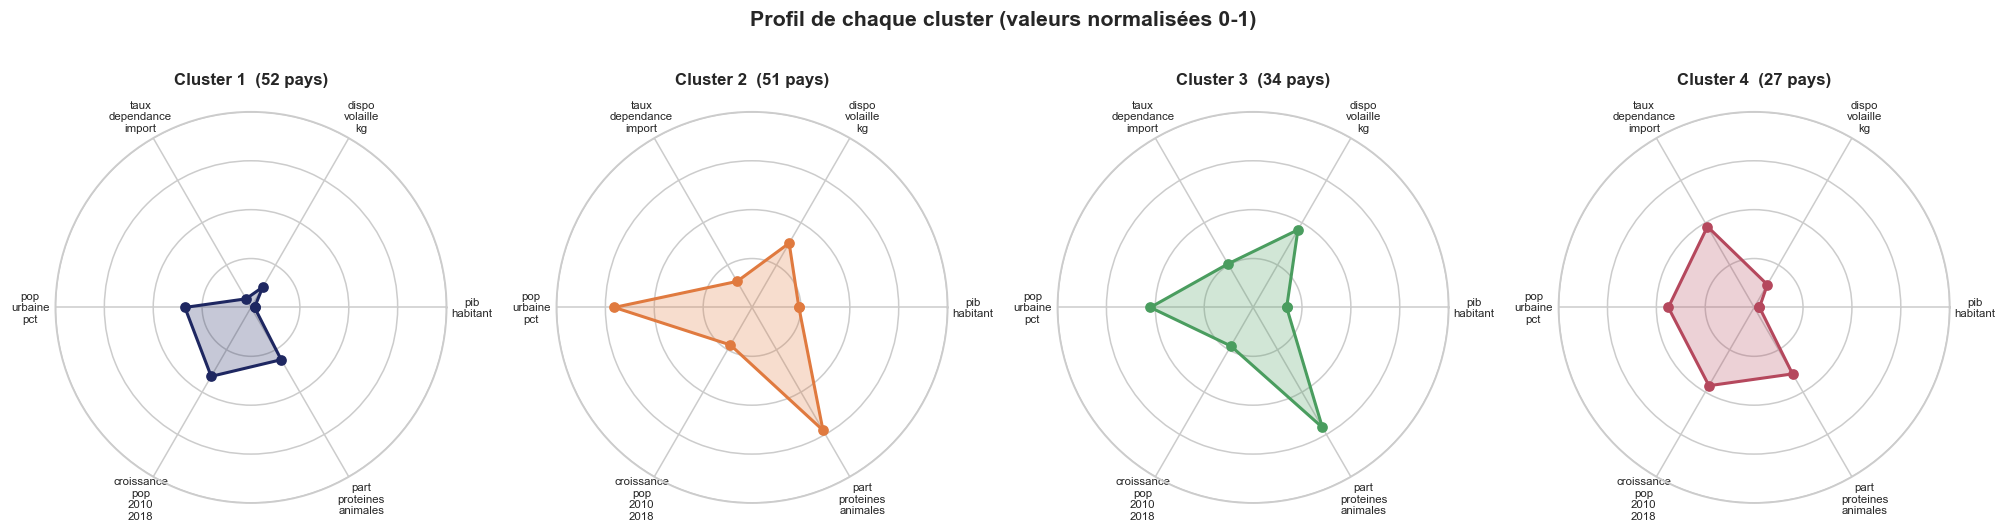

In [29]:
VARS_RADAR = ["pib_habitant", "dispo_volaille_kg", "taux_dependance_import",
              "pop_urbaine_pct", "croissance_pop_2010_2018", "part_proteines_animales"]

norm = ((df.groupby(CLUSTER)[VARS_RADAR].mean() - df[VARS_RADAR].min())
        / (df[VARS_RADAR].max() - df[VARS_RADAR].min()))

angles = np.linspace(0, 2 * np.pi, len(VARS_RADAR), endpoint=False).tolist()
angles += angles[:1]

n_clusters = len(norm)
ncols = min(4, n_clusters)
nrows = int(np.ceil(n_clusters / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.8 * nrows),
                         subplot_kw=dict(polar=True))
axes = np.atleast_1d(axes).ravel()

for i, (c, ligne) in enumerate(norm.iterrows()):
    vals = ligne.tolist() + ligne.tolist()[:1]
    ax = axes[i]
    ax.plot(angles, vals, "o-", lw=2, color=PALETTE[i % len(PALETTE)])
    ax.fill(angles, vals, alpha=.25, color=PALETTE[i % len(PALETTE)])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([v.replace("_", "\n") for v in VARS_RADAR], size=7.5)
    ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels([])
    ax.set_ylim(0, 1)
    ax.set_title(f"Cluster {c}  ({(df[CLUSTER] == c).sum()} pays)",
                 size=11, pad=18, fontweight="bold")
for ax in axes[n_clusters:]:
    ax.set_visible(False)
fig.suptitle("Profil de chaque cluster (valeurs normalisées 0-1)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">13.4 - Composition détaillée</h3>
</div>

In [30]:
titre("COMPOSITION DES CLUSTERS")
for c in sorted(df[CLUSTER].unique()):
    sous = df[df[CLUSTER] == c].sort_values("population", ascending=False)
    print(f"\n{'='*78}")
    print(f"CLUSTER {c}  —  {len(sous)} pays  —  "
          f"{sous['population'].sum():,.0f} milliers d'habitants")
    print(f"{'='*78}")
    print(f"  PIB/hab moyen        : {sous['pib_habitant'].mean():>10,.0f} USD")
    print(f"  Conso volaille       : {sous['dispo_volaille_kg'].mean():>10.1f} kg/pers/an")
    print(f"  Dépendance import    : {sous['taux_dependance_import'].mean():>10.1f} %")
    print(f"  Autosuffisance       : {sous['taux_autosuffisance'].mean():>10.1f} %")
    print(f"  Croissance démo.     : {sous['croissance_pop_2010_2018'].mean():>10.1f} %")
    print(f"  Continents           : {sous['continent'].value_counts().to_dict()}")
    print(f"\n  Pays : {', '.join(sous['pays'].tolist())}")

COMPOSITION DES CLUSTERS

CLUSTER 1  —  52 pays  —  3,436,207 milliers d'habitants
  PIB/hab moyen        :      2,416 USD
  Conso volaille       :        8.8 kg/pers/an
  Dépendance import    :       11.3 %
  Autosuffisance       :       91.5 %
  Croissance démo.     :       17.8 %
  Continents           : {'Afrique': 27, 'Asie': 16, 'Amériques': 8, 'Europe': 1}

  Pays : Inde, Indonésie, Pakistan, Nigéria, Bangladesh, Éthiopie, Philippines, Égypte, Viet Nam, République-Unie de Tanzanie, Myanmar, Kenya, Algérie, Ouganda, Soudan, Afghanistan, Maroc, Venezuela (République bolivarienne du), Mozambique, Yémen, Népal, Madagascar, Cameroun, Côte d'Ivoire, Niger, Sri Lanka, Burkina Faso, Mali, Malawi, Guatemala, Zambie, Équateur, Cambodge, Sénégal, Tchad, Zimbabwe, Rwanda, Tunisie, Bolivie (État plurinational de), Azerbaïdjan, Jordanie, Honduras, Togo, Sierra Leone, Paraguay, Liban, El Salvador, Nicaragua, Turkménistan, République centrafricaine, République de Moldova, Eswatini

CLUSTER 2  —

### Les quatre groupes, nommés

**Cluster 1 — « marchés émergents autosuffisants »** · 52 pays · 3,44 milliards d'habitants
PIB moyen 2 416 USD · consommation 8,8 kg/hab · dépendance 11,3 % · autosuffisance 91,5 % ·
croissance démographique 17,9 %. Inde, Indonésie, Pakistan, Nigéria, Bangladesh, Éthiopie,
Philippines, Égypte, Viet Nam.
**Verdict commercial :** le plus gros réservoir de population au monde, mais un pouvoir d'achat
douze fois inférieur à celui du cluster 2 et une production locale déjà couvrante.
**Pas une cible pour un produit bio aujourd'hui.**

**Cluster 2 — « puissances productives développées »** · 51 pays · 3,58 milliards d'habitants
PIB moyen 26 725 USD · consommation 27,5 kg/hab · dépendance 34,1 % · autosuffisance 113,6 % ·
urbanisation 75,1 %. Chine, États-Unis, Brésil, Russie, Japon, Allemagne, France, Royaume-Uni.
**Verdict commercial :** marchés riches mais **structurellement concurrents** — un taux
d'autosuffisance supérieur à 100 % signifie qu'ils produisent plus qu'ils ne consomment.
Quelques membres font exception avec une forte dépendance aux importations (Irlande, Arabie
saoudite, Autriche) : ils méritent un examen individuel, mené à l'étape 15.

**Cluster 3 — « petits marchés matures importateurs »** · 34 pays · 64,5 millions d'habitants
PIB moyen 19 275 USD · consommation 33,2 kg/hab, **la plus élevée des quatre groupes** ·
dépendance 57,2 % · autosuffisance 51,8 %. Cuba, Serbie, Norvège, Panama, Koweït, Uruguay,
Bosnie-Herzégovine, Arménie, Jamaïque.
**Verdict commercial :** **le profil le plus proche du client idéal** — consommation de volaille
élevée, pouvoir d'achat correct, dépendance structurelle aux importations. La réserve est le
volume : 64,5 millions d'habitants au total, soit moins que la France. Il faut donc sélectionner
à l'intérieur du groupe plutôt que le viser en bloc.

**Cluster 4 — « petits pays dépendants à faible revenu »** · 27 pays · 189 millions d'habitants
PIB moyen 3 429 USD · consommation 9,9 kg/hab · dépendance 106,2 % · autosuffisance 21,3 % ·
croissance démographique 21,6 %. Iraq, Angola, Ghana, Guinée, Bénin, Haïti, Congo, Libéria.
**Verdict commercial :** très dépendants des importations, donc commercialement accessibles,
mais **non solvables** pour un produit premium. À suivre comme marchés de moyen terme, une fois
le pouvoir d'achat consolidé.

### La lecture d'ensemble

Les deux dimensions de l'ACP se retrouvent directement dans les quatre groupes :

| | Autosuffisant (F2 positif) | Dépendant (F2 négatif) |
|---|---|---|
| **Riche** (F1 positif) | Cluster 2 — *concurrents* | Cluster 3 — **cibles** |
| **Pauvre** (F1 négatif) | Cluster 1 — *marchés futurs* | Cluster 4 — *accessibles mais non solvables* |

Ce croisement est la synthèse la plus lisible pour un comité de direction : **une seule case sur
quatre contient des clients.**

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 14 - Répartition géographique</h2>
</div>

CLUSTERS PAR CONTINENT


cluster_kmeans,1,2,3,4,Total
continent,,,,,
Afrique,27,1,1,16,45
Amériques,8,10,16,1,35
Asie,16,11,2,8,37
Europe,1,27,12,0,40
Océanie,0,2,3,2,7
Total,52,51,34,27,164


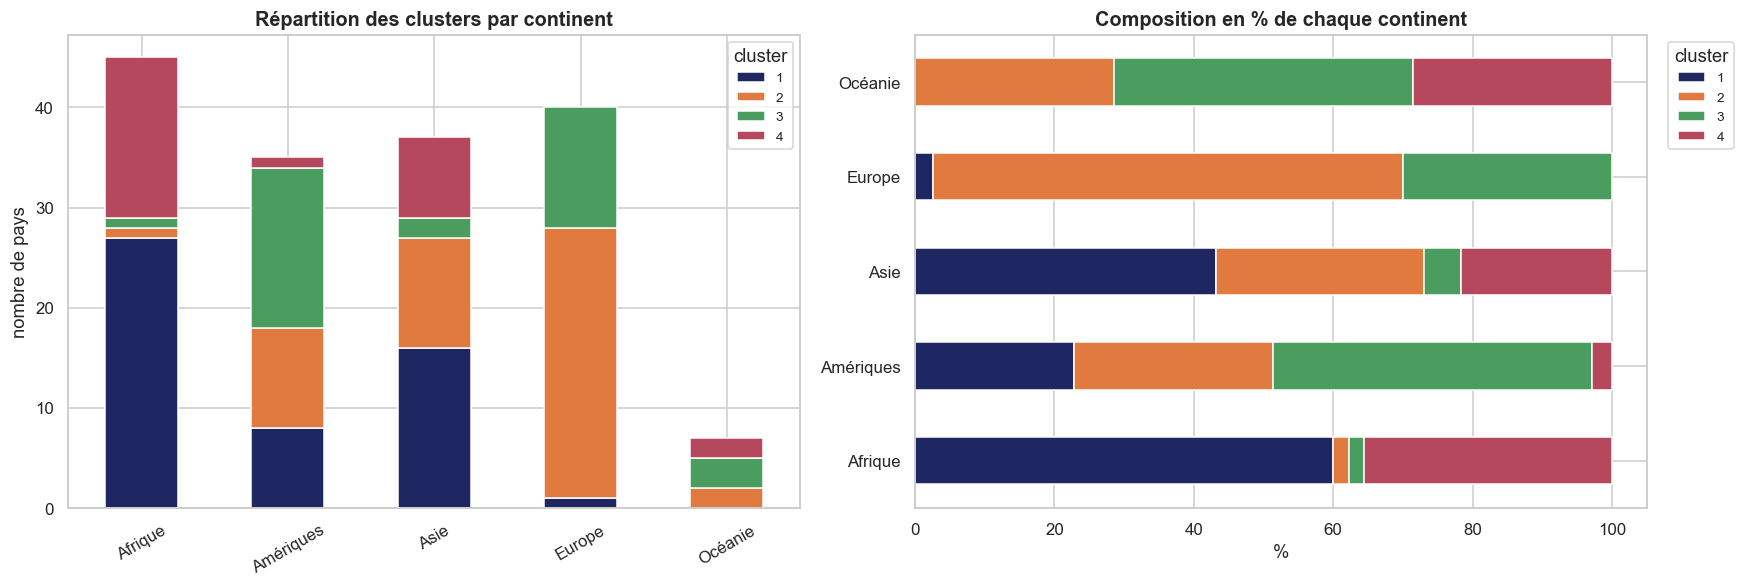

In [31]:
croise = pd.crosstab(df["continent"], df[CLUSTER], margins=True, margins_name="Total")

titre("CLUSTERS PAR CONTINENT")
display(croise)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pd.crosstab(df["continent"], df[CLUSTER]).plot(
    kind="bar", stacked=True, ax=axes[0], color=PALETTE[:K], edgecolor="white")
axes[0].set_title("Répartition des clusters par continent")
axes[0].set_xlabel(""); axes[0].set_ylabel("nombre de pays")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="cluster", fontsize=9)

(pd.crosstab(df["continent"], df[CLUSTER], normalize="index") * 100).plot(
    kind="barh", stacked=True, ax=axes[1], color=PALETTE[:K], edgecolor="white")
axes[1].set_title("Composition en % de chaque continent")
axes[1].set_xlabel("%"); axes[1].set_ylabel("")
axes[1].legend(title="cluster", fontsize=9, bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Analyse et conclusion :**

**Un cluster n'est pas un continent.** Chaque continent se répartit sur plusieurs groupes,
et chaque groupe rassemble des pays de plusieurs continents.

C'est précisément l'intérêt de la démarche : elle rapproche des pays que l'intuition géographique
n'aurait jamais associés — le Koweït et la Norvège partagent le même profil de marché, alors que
tout les sépare géographiquement.

Une segmentation commerciale par zone géographique, réflexe habituel dans l'export, serait donc
sous-optimale pour ce produit.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 15 - Du score statistique au score commercial</h2>
</div>

Le clustering identifie des groupes homogènes, mais il ne hiérarchise pas les pays à l'intérieur
d'un groupe. On construit donc un **score d'attractivité** à partir de critères explicites, pondérés
selon la stratégie de l'entreprise : un producteur de volaille **bio**, positionné sur un produit à
valeur ajoutée, qui cherche des marchés solvables et ouverts aux importations.

### Pourquoi filtrer avant de scorer

Un score appliqué à l'ensemble des pays fait remonter trois catégories de faux positifs :

| Faux positif | Exemple | Pourquoi c'est un problème |
|---|---|---|
| **Plateformes de réexport** | Pays-Bas, Belgique | taux d'importation supérieur à 100 % : ce sont des hubs logistiques, pas des marchés finaux |
| **Pays autosuffisants** | États-Unis, Israël, Australie | ils sont riches et gros consommateurs, donc bien notés, mais ils produisent tout eux-mêmes |
| **Micro-États** | Saint-Kitts, Dominique | statistiquement légitimes, commercialement négligeables |

On applique donc des **filtres d'éligibilité** avant de calculer le score.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">15.1 - Filtres d'éligibilité commerciale</h3>
</div>

In [32]:
FILTRES = {
    "population_min":     1_000,   # milliers d'hab. -> au moins 1 million
    "dependance_min":        10,   # en dessous, le pays produit l'essentiel de sa volaille
    "dependance_max":       100,   # au-dessus : réexport ou bruit d'arrondi (livrable 1, étape 13)
    "autosuffisance_max":    90,   # barrière à l'entrée trop élevée
    "pib_min":            5_000,   # produit premium : capacité à payer le surcoût bio
}

df["eligible"] = (
    (df["population"]             >= FILTRES["population_min"])     &
    (df["taux_dependance_import"] >= FILTRES["dependance_min"])     &
    (df["taux_dependance_import"] <= FILTRES["dependance_max"])     &
    (df["taux_autosuffisance"]     < FILTRES["autosuffisance_max"]) &
    (df["pib_habitant"]           >= FILTRES["pib_min"])
)

titre("FILTRES D'ÉLIGIBILITÉ COMMERCIALE")
print(f"Pays éligibles : {df['eligible'].sum()} sur {len(df)}\n")
for lib, msk in [
    ("marché trop petit (< 1 M hab.)",          df["population"] < FILTRES["population_min"]),
    ("quasi autosuffisant (import < 10 %)",     df["taux_dependance_import"] < FILTRES["dependance_min"]),
    ("réexport ou bruit d'arrondi (> 100 %)",   df["taux_dependance_import"] > FILTRES["dependance_max"]),
    ("pouvoir d'achat insuffisant (< 5 000 $)", df["pib_habitant"] < FILTRES["pib_min"]),
]:
    ex = df.loc[msk, "pays"].tolist()
    print(f"  Écartés — {lib} : {len(ex)}")
    print(f"      {', '.join(ex[:10])}{' ...' if len(ex) > 10 else ''}\n")

FILTRES D'ÉLIGIBILITÉ COMMERCIALE
Pays éligibles : 24 sur 164

  Écartés — marché trop petit (< 1 M hab.) : 24
      Antigua-et-Barbuda, Bahamas, Barbade, Belize, Cabo Verde, Djibouti, Dominique, Fidji, Grenade, Guyana ...

  Écartés — quasi autosuffisant (import < 10 %) : 53
      Algérie, Argentine, Australie, Bangladesh, Belize, Bolivie (État plurinational de), Brésil, Burkina Faso, Bélarus, Cameroun ...

  Écartés — réexport ou bruit d'arrondi (> 100 %) : 15
      Belgique, Cabo Verde, Gambie, Lettonie, Mauritanie, Mongolie, Namibie, Oman, Pays-Bas, Saint-Vincent-et-les Grenadines ...

  Écartés — pouvoir d'achat insuffisant (< 5 000 $) : 74
      Afghanistan, Algérie, Angola, Arménie, Azerbaïdjan, Bangladesh, Bolivie (État plurinational de), Burkina Faso, Bénin, Cabo Verde ...



> **Note méthodologique :** le plancher de PIB à 5 000 USD traduit une **hypothèse commerciale**, pas un fait statistique :
un poulet bio est un produit premium. Sans ce plancher, le score fait remonter des marchés très
dépendants des importations mais non solvables (Gabon, Congo, Angola). Ce paramètre doit être
discuté avec le comité de direction et peut être ajusté.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">15.2 - Score d'attractivité</h3>
</div>

In [33]:
def normaliser(s):
    """Ramène une série entre 0 et 1."""
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0


POIDS_CIBLE = {
    "taux_dependance_import":   (0.30, +1),   # critère n°1 : le pays achète déjà à l'étranger
    "dispo_volaille_kg":        (0.20, +1),   # l'habitude de consommation existe
    "pib_habitant":             (0.20, +1),   # le bio est un produit premium
    "croissance_pop_2010_2018": (0.15, +1),   # le marché de demain
    "population":               (0.10, +1),   # volume potentiel
    "inflation":                (0.05, -1),   # stabilité macro-économique
}

elig = df[df["eligible"]].copy()
sc = pd.Series(0.0, index=elig.index)
for var, (poids, sens) in POIDS_CIBLE.items():
    base = np.log1p(elig[var]) if var in ("pib_habitant", "population") else elig[var]
    n = normaliser(base)
    sc += poids * (n if sens > 0 else 1 - n)
elig["score_cible"] = (sc * 100).round(1)

df["score_cible"] = np.nan
df.loc[elig.index, "score_cible"] = elig["score_cible"]

titre("TOP 15 DES MARCHÉS CIBLES")
top = (elig.nlargest(15, "score_cible")
           [["pays", "continent", CLUSTER, "score_cible", "pib_habitant",
             "dispo_volaille_kg", "taux_dependance_import", "population",
             "croissance_pop_2010_2018"]].reset_index(drop=True))
top.index += 1
display(top)

TOP 15 DES MARCHÉS CIBLES


,pays,continent,cluster_kmeans,score_cible,pib_habitant,dispo_volaille_kg,taux_dependance_import,population,croissance_pop_2010_2018
1,Koweït,Asie,3,70.60,"29,047.65",46.25,72.49,"4,056.10",38.28
2,Irlande,Europe,2,61.10,"72,161.40",25.82,77.34,"4,753.28",5.80
3,Arabie saoudite,Asie,2,60.80,"23,929.29",43.36,50.31,"33,101.18",22.91
4,Gabon,Afrique,4,58.70,"6,921.73",29.33,97.44,"2,064.82",30.49
5,Autriche,Europe,2,50.20,"47,163.74",18.20,63.58,"8,819.90",5.72
6,Cuba,Amériques,3,49.30,"8,610.61",23.72,91.23,"11,339.25",1.00
7,Allemagne,Europe,2,48.90,"45,553.93",19.47,48.42,"82,658.41",2.84
8,Royaume-Uni de Grande-Bretagne et d'Irlande du...,Europe,2,47.80,"40,918.05",31.94,34.87,"66,727.46",5.80
9,Suisse,Europe,2,45.80,"83,610.25",15.72,38.35,"8,455.80",9.18
10,Macédoine du Nord,Europe,3,44.50,"5,955.30",19.73,97.56,"2,082.00",0.59


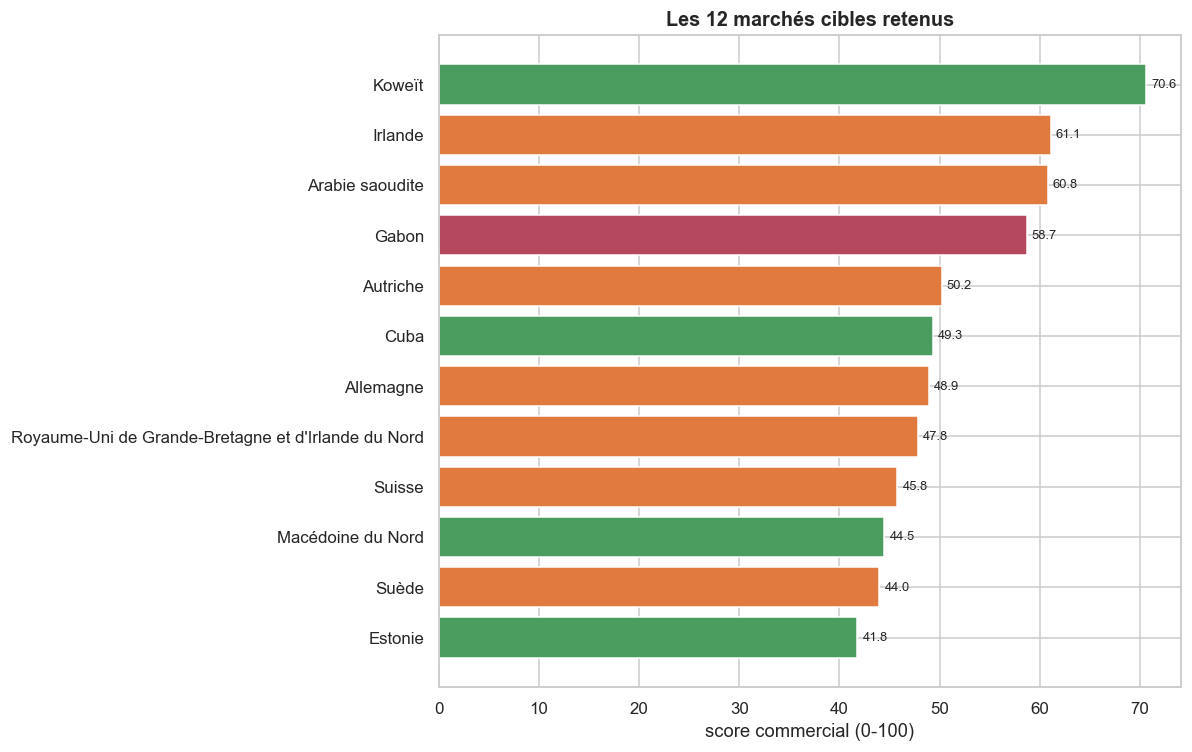

In [34]:
plt.figure(figsize=(11, 7))
t12 = elig.nlargest(12, "score_cible").sort_values("score_cible")
plt.barh(t12["pays"], t12["score_cible"],
         color=[PALETTE[(c - 1) % len(PALETTE)] for c in t12[CLUSTER]], edgecolor="white")
plt.xlabel("score commercial (0-100)")
plt.title("Les 12 marchés cibles retenus")
for i, s in enumerate(t12["score_cible"]):
    plt.text(s + .5, i, f"{s:.1f}", va="center", fontsize=8.5)
plt.tight_layout()
plt.show()

**Ce que ce graphique montre :**

Les douze marchés les mieux notés parmi les pays éligibles, classés par score décroissant.
La couleur rappelle le cluster d'appartenance.

**Analyse et conclusion :**

Le classement fait émerger **deux logiques commerciales distinctes**, ce qui est un
résultat intéressant en soi.

**La logique du Golfe** — Koweït, Arabie saoudite. Des pays riches, à consommation de volaille très
élevée (43 à 46 kg par habitant contre 20 en moyenne mondiale), structurellement incapables de
produire pour des raisons climatiques, et à croissance démographique forte (+23 % à +38 % en huit ans).
Le taux de dépendance aux importations y est structurel et durable.

**La logique européenne** — Irlande, Autriche, Allemagne, Royaume-Uni. Des marchés matures, à très
haut pouvoir d'achat, proches géographiquement, sans barrière douanière intracommunautaire, mais à
croissance démographique faible et à concurrence locale installée.

Le **Koweït** domine le classement en combinant les deux avantages : richesse et dépendance forte.

<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 16 - Conclusion et recommandations</h2>
</div>

### Réponse à la demande de Patrick

Patrick demandait des **groupements de pays** plutôt qu'une liste, et une méthode reproductible.

Les 164 pays analysés se répartissent en **quatre groupes cohérents** qui ne recoupent pas les
frontières géographiques. Un seul de ces groupes présente le profil du client recherché : marchés
matures, consommation de volaille élevée, dépendance structurelle aux importations.

À l'intérieur de ce périmètre, après application des filtres d'éligibilité commerciale, **24 pays**
restent candidats, dont un trio de tête robuste.

### Recommandation en trois horizons

| Horizon | Cible | Logique |
|---|---|---|
| **Court terme** | **Koweït, Arabie saoudite** | forte dépendance structurelle aux importations, consommation de volaille parmi les plus élevées au monde, pouvoir d'achat élevé, démographie très dynamique. Un marché test dans le Golfe permet de valider l'offre bio à l'export sur une zone où la production locale est physiquement impossible. |
| **Court terme (second front)** | **Irlande** | marché européen à très haut pouvoir d'achat, forte dépendance aux importations, absence de barrière douanière et logistique simple depuis la France. Risque faible, ticket d'entrée réduit. |
| **Moyen terme** | reste du groupe éligible (Autriche, Allemagne, Royaume-Uni, Suède, Suisse) | déploiement européen si le test irlandais est concluant. |
| **À écarter** | pays fortement autosuffisants (États-Unis, Brésil, Argentine, Israël, Australie) | barrière à l'entrée trop élevée, concurrence locale installée. |
| **À surveiller** | marchés émergents à forte croissance démographique | volume futur considérable, mais pouvoir d'achat aujourd'hui insuffisant pour un produit bio. |

### Réponse de soutenance — *« Y a-t-il un pays qui ressort plus que les autres ? »*

> Oui, mais la bonne réponse n'est pas un nom isolé. L'analyse fait émerger un **groupe** de pays au
> profil homogène, et à l'intérieur de ce groupe un classement par score. Recommander un seul pays
> serait fragile : si l'implantation échoue pour une raison locale — un accord douanier, un
> concurrent, une norme de certification — il n'y a pas de plan B. Recommander un cluster permet de
> sécuriser la stratégie et de déployer par vagues.

<div style="border:2px solid RGB(30,39,97);">
<h3 style="margin:auto;padding:15px;color:RGB(30,39,97);">16.1 - Export des résultats</h3>
</div>

In [35]:
resultats = df[["pays", "iso3", "continent", "cluster_cah", "cluster_kmeans",
                "eligible", "score_cible"] + VARS_PROFIL].copy()
for i in range(N_AXES):
    resultats[f"F{i+1}"] = coords[:, i].round(3)

resultats = resultats.sort_values("score_cible", ascending=False)
resultats.to_csv(CLEAN + "resultats_clustering.csv", index=False, encoding="utf-8")
profil.T.to_csv(CLEAN + "profils_clusters.csv", encoding="utf-8")

titre("EXPORTS RÉALISÉS")
print(f"   {CLEAN}resultats_clustering.csv   "
      f"({resultats.shape[0]} pays x {resultats.shape[1]} colonnes)")
print(f"   {CLEAN}profils_clusters.csv")
print()
display(resultats.head(15))

EXPORTS RÉALISÉS
   ../Data/clean/resultats_clustering.csv   (164 pays x 26 colonnes)
   ../Data/clean/profils_clusters.csv



,pays,iso3,continent,cluster_cah,cluster_kmeans,eligible,score_cible,population,dispo_volaille_kg,production_volaille,import_volaille,export_volaille,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,taux_dependance_import,taux_autosuffisance,croissance_pop_2010_2018,part_proteines_animales,proteines_animales,dispo_kcal_totale,F1,F2,F3,F4
78,Koweït,KWT,Asie,2,3,True,70.60,"4,056.10",46.25,56.00,137.00,4.00,"29,047.65",-4.71,100.00,2.17,72.49,29.63,38.28,47.56,47.41,"3,445.00",1.84,-1.80,2.78,-0.65
67,Irlande,IRL,Europe,3,2,True,61.10,"4,753.28",25.82,110.00,99.00,93.00,"72,161.40",10.11,62.90,0.36,77.34,85.94,5.80,57.13,60.45,"3,714.00",3.10,-0.55,-1.11,2.05
7,Arabie saoudite,SAU,Asie,3,2,True,60.80,"33,101.18",43.36,616.00,722.00,10.00,"23,929.29",1.18,83.30,-0.83,50.31,42.93,22.91,42.28,37.00,"3,194.00",1.93,-0.13,1.88,0.72
50,Gabon,GAB,Afrique,2,4,True,58.70,"2,064.82",29.33,4.00,76.00,0.00,"6,921.73",0.47,89.00,2.65,97.44,5.13,30.49,48.91,38.79,"2,640.00",-0.30,-2.50,1.79,0.23
11,Autriche,AUT,Europe,3,2,True,50.20,"8,819.90",18.20,148.00,110.00,78.00,"47,163.74",2.27,67.91,2.08,63.58,85.55,5.72,60.02,64.89,"3,694.00",3.17,-0.41,0.25,0.79
37,Cuba,CUB,Amériques,4,3,True,49.30,"11,339.25",23.72,29.00,312.00,0.00,"8,610.61",1.81,76.96,2.63,91.23,8.48,1.00,36.86,32.58,"3,409.00",0.72,-1.30,1.30,0.90
4,Allemagne,DEU,Europe,3,2,True,48.90,"82,658.41",19.47,"1,514.00",842.00,646.00,"45,553.93",2.80,80.98,1.51,48.42,87.06,2.84,60.62,63.09,"3,559.00",4.13,0.94,1.12,1.44
118,Royaume-Uni de Grande-Bretagne et d'Irlande du...,GBR,Europe,3,2,True,47.80,"66,727.46",31.94,"1,814.00",779.00,359.00,"40,918.05",3.02,82.23,2.56,34.87,81.20,5.80,56.31,58.49,"3,428.00",3.86,0.92,1.19,0.95
136,Suisse,CHE,Europe,3,2,True,45.80,"8,455.80",15.72,91.00,51.00,4.00,"83,610.25",1.42,77.91,0.53,38.35,68.42,9.18,61.32,58.54,"3,414.00",2.49,-0.77,0.11,0.19
85,Macédoine du Nord,MKD,Europe,4,3,True,44.50,"2,082.00",19.73,2.00,40.00,1.00,"5,955.30",1.08,59.74,1.35,97.56,4.88,0.59,40.87,32.91,"2,996.00",-0.27,-2.27,0.46,0.42


<div style="background-color:RGB(30,39,97);">
<h2 style="margin:auto;padding:20px;color:#fff;">Etape 17 - Limites de l'analyse</h2>
</div>

### Sur les données

+ Les bilans alimentaires FAO ne sont disponibles que pour **2017**. L'analyse est une photographie,
  pas une tendance. Une reconduction sur plusieurs millésimes permettrait de distinguer les
  dépendances structurelles des situations conjoncturelles.
+ Environ un tiers des valeurs FAO sont des données **calculées** et non standardisées.
+ La FAO arrondit les volumes au millier de tonnes. Sur les petits pays, cet arrondi produit des
  ratios aberrants — identifiés et documentés à l'étape 12 du livrable 1.
+ Cinq entités ont été **écartées et documentées** : la Corée du Nord (aucune donnée économique
  publiée par la Banque mondiale), Hong-Kong et Macao (non souveraines), la Nouvelle-Calédonie et
  la Polynésie française (marché domestique français).

### Sur la méthode

+ Le coefficient de silhouette plafonne autour de **0,29**, ce qui traduit une structure de clusters
  **faible**. C'est cohérent avec la nature des données : le développement économique est un
  continuum, pas une succession de catégories étanches. La segmentation reste un outil de décision
  valable, mais les frontières entre groupes sont poreuses.
+ L'indice de Rand ajusté entre CAH et k-means vaut **0,63**, soit un accord substantiel. Les pays
  classés différemment sont les pays frontières, à faible silhouette : leur appartenance est fragile
  et doit être signalée dans toute recommandation les concernant.
+ Les variables `proteines_animales` et `part_proteines_animales` sont corrélées à **0,93**. Elles
  pèsent donc doublement sur l'axe F1. Les conserver toutes deux était un choix — la première mesure
  un niveau, la seconde une structure de régime — mais la redondance est réelle.

### Sur les recommandations

+ Les **pondérations du score** sont un choix de l'analyste, à valider par le comité de direction.
+ Le **plancher de PIB à 5 000 USD** traduit une hypothèse commerciale sur le positionnement premium
  du produit bio. Il est paramétrable.
+ L'analyse ignore les **barrières douanières, les accords commerciaux, les normes sanitaires et les
  certifications bio locales**, qui peuvent être bloquants — la certification bio européenne n'est
  pas reconnue partout.
+ Elle ignore également les **coûts logistiques** : exporter du poulet réfrigéré vers le Golfe pose
  des contraintes de chaîne du froid qui ne figurent pas dans les données.

### Prochaine étape

Une **étude de marché terrain** sur les deux ou trois pays retenus, portant sur les circuits de
distribution, la reconnaissance du label bio français et les contraintes réglementaires
d'importation.